# TP — Chaînes de déploiement d'un modèle d'IA
## Pipeline GPU n°2 : PyTorch → TorchScript / torch.compile → CUDA → GPU

| Niveau | Composant | Rôle dans ce notebook |
|---|---|---|
| **Haut niveau** | PyTorch | ResNet-18 pré-entraîné ImageNet, tête 10 classes (section 1, commune aux 4 notebooks) |
| **Format du modèle** | graphe **TorchScript** (IR statique) · graphe **PyTorch 2 / FX** capturé par TorchDynamo | capture du graphe de calcul (4.1, 5.1) |
| **Middle level** | passes TorchScript · compilateur **Inductor** · **CUDA Graphs** | gel des poids, repliement BatchNorm, fusion, génération de kernels **Triton**, rejeu du graphe (4, 5) |
| **Bas niveau** | cuDNN / cuBLAS (convolutions) + kernels **Triton** générés par Inductor | visibles par profilage (section 6) |
| **Matériel** | GPU de Google Colab | NVIDIA T4, environnement d'exécution « GPU » |

**Modèle** : ResNet-18 pré-entraîné ImageNet, 10 classes · **Données** : 50 images de test CIFAR-10 (5 par classe) · **Batch** : 10 · **Répétitions** : 10 passes mesurées + 3 mesures d'énergie — **même protocole et mêmes fichiers que les notebooks CPU**.

### Avant de lancer
1. `Exécution` → `Modifier le type d'exécution` → **GPU T4** (même GPU que pour le notebook TensorRT).
2. `Exécution` → `Tout exécuter` et autoriser l'accès à **votre** Google Drive (dossier `MyDrive/TP_Deploiement_IA`, partagé avec le notebook GPU n°1 : les fichiers communs y sont rechargés, ou créés si ce notebook est lancé en premier).
3. Pour la comparaison des 4 pipelines (section 8) : importer les résultats envoyés par le binôme CPU, puis envoyer les vôtres avec la dernière cellule.
4. Durée : ≈ 12–15 min (dont ≈ 1 min de compilation `torch.compile` par variante), + ≈ 5 min pour l'étude optionnelle des tailles de batch.

### Plan
0. Environnement · 1. Préparation commune · 2. Outils de mesure · 3. Référence PyTorch eager GPU · 4. TorchScript · 5. torch.compile (Inductor, CUDA Graphs, FP16) · 6. Profilage bas niveau · 7. Résultats de ce pipeline · 8. Comparaison des 4 pipelines · 9. Analyse

## 0. Environnement
### 0.1 Installation
PyTorch, torchvision et **Triton** (utilisé par Inductor pour générer les kernels GPU) sont déjà installés sur Colab. `nvidia-ml-py` (NVML) mesure l'énergie du GPU ; `psutil` comme dans les autres notebooks.

In [3]:
!pip install -q nvidia-ml-py psutil
!nvidia-smi --query-gpu=name,driver_version,memory.total,power.limit,clocks.max.sm --format=csv

name, driver_version, memory.total [MiB], power.limit [W], clocks.max.sm [MHz]
Tesla T4, 580.82.07, 15360 MiB, 70.00 W, 1590 MHz


### 0.2 Configuration de l'expérience
Les paramètres expérimentaux sont **identiques dans les 4 notebooks** (images, batch, warm-up, répétitions, énergie) : ce bloc est le même que dans les notebooks CPU, seuls le nom de la session et la vérification du matériel changent.

In [4]:
import os, json, time, math, copy, hashlib, datetime, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Paramètres expérimentaux : IDENTIQUES dans les deux notebooks ----------
SEED = 42
N_IMAGES = 50            # images de test CIFAR-10
BATCH_SIZE = 10          # => 5 batches par passe
N_WARMUP = 5             # passes complètes non mesurées
N_RUNS = 10              # passes mesurées (>= 3 exigées)
ENERGY_MIN_SECONDS = 10.0
N_ENERGY_REPS = 3
N_THREADS = os.cpu_count()          # tous les vCPU, pour chaque moteur
CPU_POWER_PER_VCPU_W = 10.0         # HYPOTHÈSE utilisée seulement si RAPL est inaccessible

# ---------- Adaptation du modèle à 10 classes (si les poids n'existent pas encore) ----------
N_TRAIN_PER_CLASS = 300  # images d'entraînement par classe pour le linear probing
N_VAL = 500              # images de test (hors des 50) pour estimer la précision du modèle

# ---------- Stockage partagé par les deux notebooks (Google Drive) ----------
USE_DRIVE = True         # votre propre Google Drive : partage les fichiers entre vos 2 notebooks GPU
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/TP_Deploiement_IA"
else:
    ROOT = "/content/TP_Deploiement_IA"
SHARED, RESULTS, FIGS, WORK = f"{ROOT}/shared", f"{ROOT}/results", f"{ROOT}/figures", "/content/work"
for d in (SHARED, RESULTS, FIGS, WORK):
    os.makedirs(d, exist_ok=True)

PIPELINE_TAG = "ptgpu"
SESSION_ID = PIPELINE_TAG + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(N_THREADS)
# ---------- Spécifique GPU ----------
assert torch.cuda.is_available(), "Aucun GPU : Exécution → Modifier le type d'exécution → GPU (T4)"
DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = True   # cuDNN choisit le meilleur algorithme de convolution pour la forme d'entrée
print("Session :", SESSION_ID, "| GPU :", torch.cuda.get_device_name(0), "| dossier :", ROOT)

RUN_FP16 = True           # variante torch.compile en FP16 (Tensor Cores)
RUN_MAX_AUTOTUNE = False  # variante optionnelle torch.compile(mode="max-autotune") : compilation bien plus longue (5–15 min)
RUN_BATCH_STUDY = True    # étude complémentaire batch 1 / 10 / 50 (hors protocole commun, non utilisée dans la comparaison)
SESSION_REF_KEY = "gpu_pt_ref_eager"

Mounted at /content/drive
Session : ptgpu_20261125-172615 | GPU : Tesla T4 | dossier : /content/drive/MyDrive/TP_Deploiement_IA


### (Optionnel) Sans Google Drive : importer l'archive produite par l'autre notebook
Seulement si `USE_DRIVE = False` et que l'autre notebook a déjà été exécuté : importez `TP_Deploiement_IA.zip` (dernière cellule de l'autre notebook). Sinon, ignorez cette cellule.

In [5]:
if not USE_DRIVE and not os.path.exists(f"{SHARED}/cifar10_test50.pt"):
    import zipfile
    from google.colab import files
    print("Importez TP_Deploiement_IA.zip (ou annulez si c'est le premier notebook exécuté).")
    try:
        up = files.upload()
        with zipfile.ZipFile(next(iter(up))) as z:
            z.extractall(ROOT)
    except Exception as e:
        print("Aucune archive importée :", e)

### (Optionnel) Utiliser exactement les fichiers de votre binôme
Par défaut, la section 1 **recrée** les 50 images et la tête 10 classes avec **le même code et la même graine** que les notebooks CPU : on obtient les mêmes indices d'images (vérifiables dans l'affichage de la section 1) et un modèle équivalent. Si votre binôme peut vous envoyer ses fichiers `cifar10_test50.pt` et `resnet18_cifar10.pth` (dossier `shared` de son Drive), mettez `IMPORT_SHARED_FROM_PARTNER = True` : ils seront utilisés tels quels et les modèles seront **strictement identiques** sur les 4 pipelines.

In [6]:
IMPORT_SHARED_FROM_PARTNER = False
if IMPORT_SHARED_FROM_PARTNER:
    from google.colab import files
    print("Sélectionnez cifar10_test50.pt et resnet18_cifar10.pth (et éventuellement resnet18_cifar10.onnx, model_info.json)")
    for name, data in files.upload().items():
        base = os.path.basename(name).split(" (")[0]          # Colab renomme parfois en « fichier (1).pt »
        if base in ("cifar10_test50.pt", "resnet18_cifar10.pth", "resnet18_cifar10.onnx", "model_info.json"):
            with open(f"{SHARED}/{base}", "wb") as f:
                f.write(data)
            print("  →", f"{SHARED}/{base}")

### 0.3 Informations sur l'environnement (enregistrées avec chaque résultat)

In [7]:
import os, platform, subprocess

def _cpu_model():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

def get_env_info():
    import torch, torchvision
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "torchvision": torchvision.__version__, "cpu": _cpu_model(), "n_vcpu": os.cpu_count(),
            "torch_threads": torch.get_num_threads()}
    if torch.cuda.is_available():
        info.update({"cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                     "gpu": torch.cuda.get_device_name(0),
                     "compute_capability": ".".join(map(str, torch.cuda.get_device_capability(0)))})
        try:
            info["nvidia_driver"] = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]).decode().strip()
        except Exception:
            pass
    return info

ENV = get_env_info()
FAILED = {}   # variantes qui ont échoué (le notebook continue sans elles ; résumé à la fin)
try:
    import triton
    ENV["triton"] = triton.__version__
except ImportError:
    ENV["triton"] = "absent"
for k, v in ENV.items():
    print(f"{k:>20} : {v}")

              python : 3.13.16
               torch : 2.14.1+cu130
         torchvision : 0.29.1+cu130
                 cpu : Intel(R) Xeon(R) CPU @ 2.00GHz
              n_vcpu : 2
       torch_threads : 2
                cuda : 13.0
               cudnn : 92800
                 gpu : Tesla T4
  compute_capability : 7.5
       nvidia_driver : 580.82.07
              triton : 3.8.0


## 1. Préparation commune : modèle et données (identique dans les deux notebooks)

Cette section est **la même dans les deux notebooks**. Le premier notebook exécuté crée les fichiers dans `Drive/TP_Deploiement_IA/shared` ; le second les **recharge** au lieu de les recréer. Les deux pipelines utilisent donc exactement le même modèle et les mêmes octets d'entrée (contrôle par empreinte SHA-256).

**Données** : 50 images du jeu de **test** CIFAR-10, tirées avec une graine fixe, **5 par classe** (sous-ensemble équilibré).

**Prétraitement** (fonction unique `preprocess_uint8`) :
1. `uint8 [0,255]` → `float32 [0,1]` ;
2. redimensionnement **32×32 → 224×224** (bilinéaire), résolution d'entraînement de ResNet-18 ;
3. normalisation avec les statistiques ImageNet du pré-entraînement : `mean=(0.485, 0.456, 0.406)`, `std=(0.229, 0.224, 0.225)`.

**Modèle à 10 classes** : ResNet-18 pré-entraîné ImageNet sort 1000 classes. On garde tout le réseau pré-entraîné **gelé** et on remplace la dernière couche `fc` (512 → 1000) par une couche 512 → 10 apprise sur des images d'**entraînement** CIFAR-10 (*linear probing*, ≈ 2–3 min sur CPU). Si un fichier de poids existe déjà dans `shared` (par exemple créé par le notebook GPU d'un binôme), il est réutilisé tel quel.

In [8]:
# Téléchargement rapide de CIFAR-10 (miroir Hugging Face ; torchvision vérifie le MD5 officiel)
import os, hashlib
P = "/content/data/cifar-10-python.tar.gz"
MD5_OK = "c58f30108f718f92721af3b95e74349a"
os.makedirs("/content/data", exist_ok=True)
if os.path.exists(P) and hashlib.md5(open(P, "rb").read()).hexdigest() != MD5_OK: os.remove(P)
if not os.path.exists(P): os.system(f"wget -q -O {P} https://huggingface.co/cloneofsimo/test_model/resolve/main/cifar-10-python.tar.gz")
print("MD5 :", hashlib.md5(open(P, "rb").read()).hexdigest(), "| attendu :", MD5_OK)

MD5 : c58f30108f718f92721af3b95e74349a | attendu : c58f30108f718f92721af3b95e74349a


In [9]:
# ---------- Modèle et prétraitement (définitions communes) ----------
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 10
IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def build_model(num_classes=NUM_CLASSES, pretrained=True):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def preprocess_uint8(x_uint8_nhwc):
    # uint8 [N,32,32,3] -> float32 [N,3,224,224] normalisé ImageNet
    x = x_uint8_nhwc.permute(0, 3, 1, 2).float().div(255.0)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    mean = torch.tensor(MEAN, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

PREPROCESSING = {"resize": [IMG_SIZE, IMG_SIZE], "interpolation": "bilinear, align_corners=False",
                 "scale": "1/255", "mean": list(MEAN), "std": list(STD), "layout": "NCHW float32"}

TEST50_PATH = f"{SHARED}/cifar10_test50.pt"
WEIGHTS_PATH = f"{SHARED}/resnet18_cifar10.pth"
MODEL_INFO_PATH = f"{SHARED}/model_info.json"
ONNX_PATH = f"{SHARED}/resnet18_cifar10.onnx"

train_set = torchvision.datasets.CIFAR10("/content/data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("/content/data", train=False, download=True)
CLASSES = test_set.classes

Sous-ensemble existant rechargé : /content/drive/MyDrive/TP_Deploiement_IA/shared/cifar10_test50.pt
Images : (50, 3, 224, 224) torch.float32 | par classe : [5 5 5 5 5 5 5 5 5 5]
Indices CIFAR-10 (test) : [347, 883, 1020, 1216, 1381, 1626, 1658, 1870, 2285, 2786, 3138, 3316, 3534, 3802, 4064, 4244, 4297, 4374, 4426, 4492, 4542, 4589, 4609, 4623, 4811, 5052, 5217, 5486, 5501, 6056, 6274, 6574, 6733, 6999, 7075, 7450, 7527, 7638, 7662, 7701, 8118, 8181, 8363, 8430, 8452, 8901, 9149, 9651, 9652, 9763]
SHA-256 des entrées : 117a8d622a1424ccdda5f77c957bd3794f6b3a54ff4d94a690b53d19052a30f9


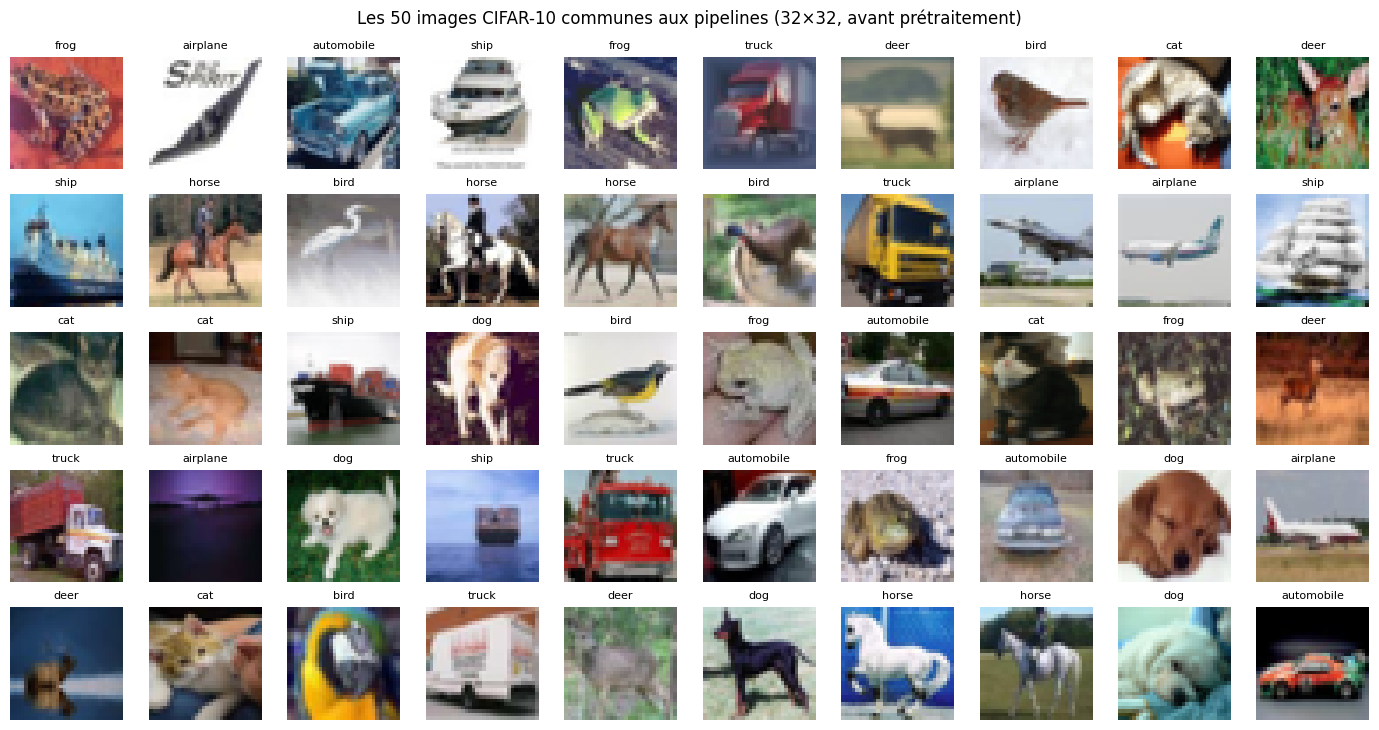

In [10]:
# ---------- 1.1 Sous-ensemble des 50 images (créé une seule fois, puis rechargé) ----------
if not os.path.exists(TEST50_PATH):
    labels_test = np.array(test_set.targets)
    rng = np.random.default_rng(SEED)
    idx = np.sort(np.concatenate([
        rng.choice(np.where(labels_test == c)[0], N_IMAGES // NUM_CLASSES, replace=False)
        for c in range(NUM_CLASSES)]))
    x50_uint8 = torch.from_numpy(test_set.data[idx])
    y50 = torch.from_numpy(labels_test[idx]).long()
    x50 = preprocess_uint8(x50_uint8).contiguous()
    torch.save({"images": x50, "labels": y50, "images_uint8": x50_uint8, "indices": idx.tolist(),
                "classes": CLASSES, "preprocessing": PREPROCESSING,
                "sha256": hashlib.sha256(x50.numpy().tobytes()).hexdigest()}, TEST50_PATH)
    print("Sous-ensemble créé :", TEST50_PATH)
else:
    print("Sous-ensemble existant rechargé :", TEST50_PATH)

T50 = torch.load(TEST50_PATH, weights_only=False)
X50, Y50 = T50["images"].contiguous(), T50["labels"]
Y50_NP = Y50.numpy()
X50_NP = np.ascontiguousarray(X50.numpy())
TEST_SHA = hashlib.sha256(X50.numpy().tobytes()).hexdigest()
assert TEST_SHA == T50["sha256"], "Empreinte des images incohérente"
assert T50["preprocessing"] == PREPROCESSING, "Paramètres de prétraitement différents"
print("Images :", tuple(X50.shape), X50.dtype, "| par classe :", np.bincount(Y50_NP))
print("Indices CIFAR-10 (test) :", T50["indices"])
print("SHA-256 des entrées :", TEST_SHA)

fig, axes = plt.subplots(5, 10, figsize=(14, 7.4))
for ax, img, lab in zip(axes.ravel(), T50["images_uint8"], Y50_NP):
    ax.imshow(img.numpy()); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
fig.suptitle("Les 50 images CIFAR-10 communes aux pipelines (32×32, avant prétraitement)")
plt.tight_layout(); plt.show()

In [11]:
# ---------- 1.2 Modèle 10 classes (créé une seule fois, puis rechargé) ----------
@torch.no_grad()
def extract_features(backbone, x_uint8, bs=100):
    out = []
    for i in range(0, len(x_uint8), bs):
        out.append(backbone(preprocess_uint8(torch.from_numpy(x_uint8[i:i + bs]))).flatten(1))
    return torch.cat(out)

if not os.path.exists(WEIGHTS_PATH):
    print("Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…")
    torch.manual_seed(SEED)
    model = build_model(pretrained=True).eval()
    backbone = nn.Sequential(*list(model.children())[:-1]).eval()     # tout sauf fc -> [N,512,1,1]
    rng = np.random.default_rng(SEED)
    ytr_all, yte_all = np.array(train_set.targets), np.array(test_set.targets)
    tr_idx = np.sort(np.concatenate([rng.choice(np.where(ytr_all == c)[0], N_TRAIN_PER_CLASS, replace=False)
                                     for c in range(NUM_CLASSES)]))
    pool = np.setdiff1d(np.arange(len(yte_all)), np.array(T50["indices"]))   # jamais les 50 images
    va_idx = np.sort(rng.choice(pool, N_VAL, replace=False))
    t0 = time.time()
    f_tr = extract_features(backbone, train_set.data[tr_idx])
    f_va = extract_features(backbone, test_set.data[va_idx])
    print(f"Extraction des caractéristiques : {time.time() - t0:.0f} s")
    y_tr, y_va = torch.from_numpy(ytr_all[tr_idx]).long(), torch.from_numpy(yte_all[va_idx]).long()
    head = nn.Linear(512, NUM_CLASSES)
    opt = torch.optim.Adam(head.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in range(500):
        opt.zero_grad()
        loss = F.cross_entropy(head(f_tr), y_tr)
        loss.backward(); opt.step()
    with torch.no_grad():
        acc_tr = (head(f_tr).argmax(1) == y_tr).float().mean().item() * 100
        acc_va = (head(f_va).argmax(1) == y_va).float().mean().item() * 100
    print(f"Tête 10 classes : perte {loss.item():.3f} | Top-1 entraînement {acc_tr:.1f} % | validation {acc_va:.1f} %")
    model.fc.load_state_dict(head.state_dict())
    torch.save(model.state_dict(), WEIGHTS_PATH)
    with open(MODEL_INFO_PATH, "w") as f:
        json.dump({"base": "torchvision resnet18 IMAGENET1K_V1 (gelé)", "head": "Linear(512,10)",
                   "method": "linear probing", "train_images": int(len(tr_idx)),
                   "val_images": int(len(va_idx)), "val_top1_pct": acc_va}, f, indent=2)
    del model, backbone, f_tr, f_va
else:
    print("Poids existants rechargés :", WEIGHTS_PATH)

model_ref = build_model(pretrained=False)
model_ref.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
model_ref.eval()
if os.path.exists(MODEL_INFO_PATH):
    with open(MODEL_INFO_PATH) as f:
        print("Modèle :", json.load(f))

Poids existants rechargés : /content/drive/MyDrive/TP_Deploiement_IA/shared/resnet18_cifar10.pth
Modèle : {'base': 'torchvision resnet18 IMAGENET1K_V1 (gelé)', 'head': 'Linear(512,10)', 'method': 'linear probing', 'train_images': 3000, 'val_images': 500, 'val_top1_pct': 80.80000281333923}


In [12]:
# ---------- Spécifique GPU : entrées et modèle copiés une fois sur le GPU ----------
# Le transfert hôte → GPU n'est pas chronométré (comme le prétraitement côté CPU).
X50_GPU = X50.to(DEVICE).contiguous()
model_gpu = copy.deepcopy(model_ref).to(DEVICE).eval()
WEIGHTS_SHA = hashlib.sha256(open(WEIGHTS_PATH, "rb").read()).hexdigest()
# Enregistré avec chaque résultat : permet de vérifier, lors de la comparaison, que les 4 pipelines
# ont utilisé les mêmes images (indices) et le même modèle (empreinte des poids).
COMMON_EXTRA = {"test_indices": [int(i) for i in T50["indices"]], "weights_sha256": WEIGHTS_SHA}
print("Entrées sur", X50_GPU.device, "| SHA-256 (calculé sur les octets CPU, identique aux notebooks CPU) :", TEST_SHA[:16],
      "| poids :", WEIGHTS_SHA[:16])

Entrées sur cuda:0 | SHA-256 (calculé sur les octets CPU, identique aux notebooks CPU) : 117a8d622a1424cc | poids : 5af8ec3a559c95b0


## 2. Outils de mesure (identiques dans les deux notebooks)

**Protocole commun à tous les pipelines :**
* 50 images → **5 batches de 10**, entrées prétraitées une fois pour toutes (le prétraitement n'est pas chronométré) ;
* **5 passes de warm-up** non mesurées : allocations mémoire, compilation JIT / optimisation de graphe à la volée, remplissage des caches ;
* **10 passes mesurées** (≥ 3 exigées) chronométrées avec `time.perf_counter()` ;
* par passe : **temps d'inférence** des 50 images, **débit** = 50 / temps (images/s), **latence par batch** (moyenne, médiane, max), **précision Top-1**, accord avec la 1re passe ;
* pour chaque indicateur : **moyenne, écart-type, minimum, maximum, coefficient de variation** (CV = σ / moyenne) ;
* chaque exécution complète du notebook est enregistrée dans `results/history/` : relancer le notebook dans une nouvelle session ajoute une **exécution indépendante** (voir la dernière section).

**Énergie CPU** :
* **RAPL** (*Running Average Power Limit*, compteur d'énergie du package CPU dans `/sys/class/powercap`) est utilisé s'il est accessible → valeur **mesurée** ;
* sur les VM Colab, RAPL n'est en général **pas exposé** ; on calcule alors une **estimation** `E ≈ P_vCPU × temps CPU actif`, où le temps CPU actif (somme sur tous les vCPU) est lu par `psutil` et `P_vCPU = CPU_POWER_PER_VCPU_W` (hypothèse : un Xeon serveur ≈ 200 W pour 20–40 threads, soit ≈ 5–10 W par thread actif).
* La méthode utilisée est enregistrée avec chaque résultat. ⚠ Une estimation doit être présentée comme telle dans le rapport : elle est proportionnelle au temps CPU consommé, donc elle compare correctement les pipelines entre eux, mais sa valeur absolue dépend de l'hypothèse.

**Énergie GPU** (remplace la cellule « énergie CPU » des notebooks CPU, même interface `meter_factory`) :
* la bibliothèque **NVML** (celle de `nvidia-smi`) donne le **compteur d'énergie de la carte GPU** (mJ, disponible depuis l'architecture Volta : T4, L4, A100) → valeur **mesurée** ;
* si ce compteur n'existe pas, on échantillonne la puissance toutes les 50 ms et on l'intègre dans le temps ;
* la **puissance de repos** du GPU est mesurée au départ pour calculer l'énergie **nette** ;
* ⚠ seule la carte GPU est mesurée (ni le CPU hôte, ni la RAM) ; côté CPU l'énergie est en général **estimée** : le rapport doit le préciser lorsqu'il compare les deux plateformes.

In [13]:
# ============================================================
# Outils de mesure — IDENTIQUES dans les deux notebooks
# ============================================================
import os, time, json, datetime, glob
import numpy as np

def _to_py(o):
    # Conversion récursive numpy -> types Python (pour json.dump)
    if isinstance(o, dict):
        return {k: _to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_to_py(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o

def describe(values):
    # Moyenne, écart-type (échantillon, ddof=1), min, max, coefficient de variation
    a = np.asarray(values, dtype=float)
    mean = float(a.mean())
    std = float(a.std(ddof=1)) if a.size > 1 else 0.0
    return {"mean": mean, "std": std, "min": float(a.min()), "max": float(a.max()),
            "cv_pct": (100.0 * std / mean) if mean else 0.0, "n": int(a.size)}

def to_numpy(out):
    if isinstance(out, np.ndarray):
        return out
    return out.detach().float().cpu().numpy()

def make_batches(images, batch_size):
    return [images[i:i + batch_size] for i in range(0, len(images), batch_size)]

def run_pass(infer_fn, batches, sync_fn, keep_outputs=True):
    # Une passe complète sur les 50 images. sync_fn() garantit que le calcul
    # est terminé avant d'arrêter le chronomètre (indispensable sur GPU : CUDA est asynchrone).
    outs, lat = [], []
    t0 = time.perf_counter()
    for xb in batches:
        ts = time.perf_counter()
        out = infer_fn(xb)
        sync_fn()
        lat.append(time.perf_counter() - ts)
        if keep_outputs:
            outs.append(out)
    return time.perf_counter() - t0, lat, outs

RUN_METRICS = ["total_time_ms", "throughput_img_s", "batch_latency_mean_ms",
               "batch_latency_p50_ms", "batch_latency_max_ms", "per_image_time_ms",
               "top1_acc_pct", "agreement_with_run0_pct"]
ENERGY_METRICS = ["energy_per_image_mj", "net_energy_per_image_mj", "mean_power_w",
                  "energy_j", "duration_s"]

def benchmark(infer_fn, images, labels_np, sync_fn, batch_size=None, n_warmup=None, n_runs=None):
    batch_size = batch_size or BATCH_SIZE
    n_warmup = N_WARMUP if n_warmup is None else n_warmup
    n_runs = n_runs or N_RUNS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    # 1) Warm-up : non mesuré (allocations, autotuning cuDNN, compilation JIT, montée en fréquence)
    for _ in range(n_warmup):
        run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
    # 2) Répétitions mesurées
    runs, logits0 = [], None
    for r in range(n_runs):
        total, lat, outs = run_pass(infer_fn, batches, sync_fn)
        logits = np.concatenate([to_numpy(o) for o in outs]).astype(np.float32)
        preds = logits.argmax(1)
        if logits0 is None:
            logits0 = logits
        lat_ms = np.asarray(lat) * 1e3
        runs.append({
            "run": r,
            "total_time_ms": total * 1e3,
            "throughput_img_s": n / total,
            "batch_latency_mean_ms": float(lat_ms.mean()),
            "batch_latency_p50_ms": float(np.percentile(lat_ms, 50)),
            "batch_latency_max_ms": float(lat_ms.max()),
            "per_image_time_ms": total * 1e3 / n,
            "top1_acc_pct": float((preds == labels_np).mean() * 100),
            "agreement_with_run0_pct": float((preds == logits0.argmax(1)).mean() * 100),
        })
    return runs, logits0

def measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w=0.0,
                   batch_size=None, min_seconds=None, n_reps=None):
    # Boucle de passes complètes pendant au moins `min_seconds` secondes,
    # pour que la mesure d'énergie couvre une durée exploitable.
    batch_size = batch_size or BATCH_SIZE
    min_seconds = min_seconds or ENERGY_MIN_SECONDS
    n_reps = n_reps or N_ENERGY_REPS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    reps = []
    for r in range(n_reps):
        n_img = 0
        with meter_factory() as m:
            t0 = time.perf_counter()
            while time.perf_counter() - t0 < min_seconds:
                run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
                n_img += n
        e, dur = m.energy_j, m.duration_s
        reps.append({"rep": r, "method": m.method, "energy_j": e, "duration_s": dur,
                     "images": n_img, "mean_power_w": e / dur,
                     "energy_per_image_mj": 1e3 * e / n_img,
                     "net_energy_per_image_mj": 1e3 * max(e - idle_power_w * dur, 0.0) / n_img})
    return reps

def save_result(key, label, platform_name, family, precision, runs, logits,
                energy_reps=None, idle_power_w=None, extra=None):
    res = {
        "key": key, "label": label, "platform": platform_name, "family": family,
        "precision": precision, "batch_size": BATCH_SIZE, "n_images": int(len(logits)),
        "n_warmup": N_WARMUP, "n_runs": len(runs), "runs": runs,
        "summary": {m: describe([r[m] for r in runs]) for m in RUN_METRICS},
        "energy": None, "env": ENV, "test_sha256": TEST_SHA, "extra": extra or {},
        "session_id": globals().get("SESSION_ID"), "session_ref_key": globals().get("SESSION_REF_KEY"),
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    if energy_reps:
        res["energy"] = {"method": energy_reps[0]["method"], "idle_power_w": idle_power_w,
                         "reps": energy_reps,
                         "summary": {m: describe([e[m] for e in energy_reps]) for m in ENERGY_METRICS}}
    np.save(f"{RESULTS}/{key}_logits.npy", logits)
    with open(f"{RESULTS}/{key}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    # historique : une copie par session, pour analyser la variabilité entre exécutions indépendantes
    os.makedirs(f"{RESULTS}/history", exist_ok=True)
    with open(f"{RESULTS}/history/{key}__{res['session_id']}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    s = res["summary"]
    msg = (f"[{label}] débit = {s['throughput_img_s']['mean']:.1f} ± {s['throughput_img_s']['std']:.1f} img/s"
           f" | latence/batch = {s['batch_latency_mean_ms']['mean']:.2f} ± {s['batch_latency_mean_ms']['std']:.2f} ms"
           f" | Top-1 = {s['top1_acc_pct']['mean']:.1f} %")
    if res["energy"]:
        msg += f" | énergie/image = {res['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
    print(msg)
    return res

def evaluate_pipeline(key, label, platform_name, family, precision, infer_fn, images, sync_fn,
                      meter_factory=None, idle_power_w=0.0, extra=None):
    runs, logits = benchmark(infer_fn, images, Y50_NP, sync_fn)
    reps = measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w) if meter_factory else None
    return save_result(key, label, platform_name, family, precision, runs, logits,
                       energy_reps=reps, idle_power_w=idle_power_w, extra=extra)

print("Outils de mesure prêts.")

Outils de mesure prêts.


In [14]:
# ---------- Mesure d'énergie GPU (NVML) ----------
import threading
try:
    import pynvml
    pynvml.nvmlInit()
    NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
except Exception as e:
    pynvml, NVML_HANDLE = None, None
    print("NVML indisponible :", e)

def _nvml_energy_mj():
    try:
        return pynvml.nvmlDeviceGetTotalEnergyConsumption(NVML_HANDLE)
    except Exception:
        return None

def _nvml_power_w():
    return pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE) / 1000.0

class GpuEnergyMeter:
    """Même interface que CpuEnergyMeter : attributs energy_j, duration_s, method."""
    interval_s = 0.05

    def _loop(self):
        while not self._stop.is_set():
            self._samples.append((time.perf_counter(), _nvml_power_w()))
            time.sleep(self.interval_s)

    def __enter__(self):
        torch.cuda.synchronize()
        self._samples, self._stop = [], threading.Event()
        self._e0 = _nvml_energy_mj()
        self._th = threading.Thread(target=self._loop, daemon=True)
        self._t0 = time.perf_counter()
        self._th.start()
        return self

    def __exit__(self, *exc):
        torch.cuda.synchronize()
        self.duration_s = time.perf_counter() - self._t0
        e1 = _nvml_energy_mj()
        self._stop.set(); self._th.join()
        if self._e0 is not None and e1 is not None and e1 > self._e0:
            self.energy_j = (e1 - self._e0) / 1000.0
            self.method = "NVML : compteur d'énergie de la carte GPU (mesuré)"
        else:
            ts = np.array([s[0] for s in self._samples]); ps = np.array([s[1] for s in self._samples])
            trapz = getattr(np, "trapezoid", None) or np.trapz
            self.energy_j = float(trapz(ps, ts)) if len(ts) > 1 else float("nan")
            self.method = "NVML : puissance échantillonnée × temps (mesuré)"
        self.peak_power_w = max((p for _, p in self._samples), default=float("nan"))
        return False

def measure_idle_power_gpu(seconds=5.0):
    torch.cuda.synchronize(); time.sleep(2.0)
    with GpuEnergyMeter() as m:
        time.sleep(seconds)
    return m.energy_j / m.duration_s

def cuda_sync():
    torch.cuda.synchronize()     # CUDA est asynchrone : on attend la fin réelle du calcul

GPU_METER = GpuEnergyMeter if NVML_HANDLE is not None else None
IDLE_W = measure_idle_power_gpu() if GPU_METER else 0.0
print(f"NVML accessible : {GPU_METER is not None} | puissance GPU au repos : {IDLE_W:.1f} W")

NVML accessible : True | puissance GPU au repos : 27.9 W


## 3. Référence : PyTorch eager FP32 sur GPU (dans cette session)
Exécution « interprétée » : Python appelle chaque opérateur l'un après l'autre et **chaque opérateur lance son propre kernel CUDA** (convolution cuDNN, BatchNorm, ReLU, addition…), chaque résultat intermédiaire étant écrit puis relu dans la mémoire du GPU. Mesurée **sur la même machine**, elle sert de base aux accélérations et à la vérification des prédictions.

In [15]:
@torch.inference_mode()
def infer_eager_gpu(x):
    return model_gpu(x)

res_ref = evaluate_pipeline("gpu_pt_ref_eager", "Réf. eager FP32 (session PT-GPU)", "GPU", "reference", "FP32",
                            infer_eager_gpu, X50_GPU, cuda_sync, GPU_METER, IDLE_W, extra=COMMON_EXTRA)

[Réf. eager FP32 (session PT-GPU)] débit = 980.1 ± 34.8 img/s | latence/batch = 10.21 ± 0.40 ms | Top-1 = 90.0 % | énergie/image = 71.86 mJ


## 4. Pipeline GPU n°2-a : PyTorch → TorchScript → CUDA → GPU

### 4.1 Format du modèle : graphe TorchScript
Même préparation que dans le notebook CPU n°2, mais sur le GPU :
* `torch.jit.trace` enregistre le **graphe statique** des opérations sur un batch exemple (ici déjà sur le GPU) ;
* `torch.jit.freeze` intègre poids et attributs comme **constantes** ;
* `torch.jit.optimize_for_inference` applique les passes d'inférence (notamment **repliement BatchNorm dans la convolution**) ; sur GPU les convolutions restent des appels cuDNN, et l'exécuteur TorchScript peut **fusionner** des opérations élément par élément (fuser NVFuser/NNC selon la version).

In [16]:
from collections import Counter
import pandas as pd

def graph_ops(scripted):
    return Counter(n.kind() for n in scripted.graph.nodes() if n.kind() != "prim::Constant")

TS_OK = True
try:
    t0 = time.perf_counter()
    with torch.no_grad():
        ts_traced = torch.jit.trace(copy.deepcopy(model_gpu).eval(), X50_GPU[:BATCH_SIZE])
        ts_frozen = torch.jit.freeze(ts_traced.eval())
        ops_frozen = graph_ops(ts_frozen)
        try:
            ts_opt = torch.jit.optimize_for_inference(ts_frozen)
            ts_opt(X50_GPU[:BATCH_SIZE]); torch.cuda.synchronize()     # vérifie que le graphe optimisé s'exécute
            OPT_OK = True
        except Exception as e:
            print("optimize_for_inference indisponible sur GPU, on garde le graphe gelé :", repr(e)[:200])
            ts_opt, OPT_OK = ts_frozen, False
        ops_opt = graph_ops(ts_opt)
    ts_prep_s = time.perf_counter() - t0
    kinds = sorted(set(ops_frozen) | set(ops_opt), key=lambda k: -(ops_frozen.get(k, 0) + ops_opt.get(k, 0)))
    ts_table = pd.DataFrame({"après trace + freeze": [ops_frozen.get(k, 0) for k in kinds],
                             "après optimize_for_inference": [ops_opt.get(k, 0) for k in kinds]}, index=kinds)
    print(f"Préparation TorchScript : {ts_prep_s:.1f} s | opérations : {sum(ops_frozen.values())} → {sum(ops_opt.values())}")
    display(ts_table)
except Exception as e:
    TS_OK = False
    FAILED["TorchScript (préparation)"] = repr(e)
    print("⚠ TorchScript indisponible, variante ignorée :", repr(e))

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:106: FutureWarning: `torch.jit.freeze` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_freeze.py:230: FutureWarning: `torch.jit.optimize_for_inference` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Préparation TorchScript : 1.1 s | opérations : 49 → 25


,après trace + freeze,après optimize_for_inference
aten::_convolution,20,0
aten::relu_,17,0
aten::cudnn_convolution_relu,0,9
aten::cudnn_convolution_add_relu,0,8
aten::add_,8,0
aten::conv2d,0,3
aten::adaptive_avg_pool2d,1,1
aten::max_pool2d,1,1
aten::flatten,1,1
aten::add,0,1


### 4.2 Contrôle numérique puis mesures (TorchScript FP32)
Un graphe TorchScript passe par quelques exécutions de **profilage/optimisation** au début (*profiling executor*) : elles ont lieu pendant le warm-up et ne sont donc pas mesurées.

In [17]:
@torch.inference_mode()
def infer_ts(x):
    return ts_opt(x)

with torch.inference_mode():
    ref_logits = np.concatenate([to_numpy(model_gpu(X50_GPU[i:i + BATCH_SIZE])) for i in range(0, N_IMAGES, BATCH_SIZE)])
if TS_OK:
    try:
        ts_logits = np.concatenate([to_numpy(infer_ts(X50_GPU[i:i + BATCH_SIZE])) for i in range(0, N_IMAGES, BATCH_SIZE)])
        print(f"max |logit eager − logit TorchScript| = {np.abs(ref_logits - ts_logits).max():.2e} | "
              f"accord Top-1 = {100 * (ref_logits.argmax(1) == ts_logits.argmax(1)).mean():.0f} %")
        res_ts = evaluate_pipeline("gpu2_torchscript_fp32", "GPU-2 TorchScript FP32", "GPU", "pipeline2", "FP32",
                                   infer_ts, X50_GPU, cuda_sync, GPU_METER, IDLE_W,
                                   extra={**COMMON_EXTRA, "prep_time_s": ts_prep_s, "optimize_for_inference": OPT_OK,
                                          "ops_frozen": sum(ops_frozen.values()), "ops_optimized": sum(ops_opt.values())})
    except Exception as e:
        TS_OK = False
        FAILED["TorchScript (mesures)"] = repr(e)
        print("⚠ Mesures TorchScript impossibles, variante ignorée :", repr(e))

max |logit eager − logit TorchScript| = 6.68e-05 | accord Top-1 = 100 %
[GPU-2 TorchScript FP32] débit = 1152.5 ± 9.0 img/s | latence/batch = 8.68 ± 0.07 ms | Top-1 = 90.0 % | énergie/image = 60.55 mJ


## 5. Pipeline GPU n°2-b : PyTorch → torch.compile (TorchDynamo + Inductor) → CUDA → GPU

### 5.1 Format du modèle : capture du graphe par TorchDynamo
TorchDynamo intercepte l'exécution Python et produit un graphe **FX**. `explain` indique combien de graphes ont été capturés et s'il y a des **ruptures de graphe** (*graph breaks*). Pour ResNet-18 : un seul graphe, aucune rupture attendue.

In [18]:
import torch._dynamo
import torch._inductor.config as inductor_config
torch._dynamo.reset()
try:
    with torch.inference_mode():
        ex = torch._dynamo.explain(copy.deepcopy(model_gpu).eval())(X50_GPU[:BATCH_SIZE])
    print(f"Graphes capturés : {ex.graph_count} | ruptures : {ex.graph_break_count} | opérations FX : {ex.op_count}")
except Exception as e:
    print("explain indisponible :", e)
torch._dynamo.reset()

Graphes capturés : 1 | ruptures : 0 | opérations FX : 69


### 5.2 Middle level : compilation par Inductor (GPU)
Mêmes réglages que dans le notebook CPU n°2, plus deux réglages propres au GPU :
* **torch.compile (défaut)** : Inductor fusionne les opérations élément par élément (BatchNorm, ReLU, addition résiduelle) en kernels **Triton** générés et compilés pour ce GPU ; les convolutions restent des appels cuDNN.
* **torch.compile + freezing** : poids traités comme des **constantes** → BatchNorm **repliée dans les convolutions**, moins d'opérations à exécuter.
* **+ CUDA Graphs** (`mode="reduce-overhead"`) : toute la séquence de kernels d'un batch est enregistrée une fois puis **rejouée en un seul appel**, ce qui supprime le coût de lancement de chaque kernel depuis le CPU (important avec de petits batches).
* **FP16** (+ freezing + CUDA Graphs) : modèle en demi-précision sur les **Tensor Cores**, pour comparer avec TensorRT FP16.

Le **premier appel déclenche la compilation** : son temps est mesuré à part (coût payé une fois au déploiement) et exclu du débit. Avec CUDA Graphs, la sortie est copiée (`clone`, 10×10 valeurs) car sa mémoire est réutilisée au rejeu suivant.

In [19]:
# ---------- Profilage GPU : quels kernels CUDA sont réellement exécutés ? ----------
from torch.profiler import profile, ProfilerActivity

def _dev_time_us(e):
    for attr in ("device_time_total", "cuda_time_total", "device_time", "cuda_time"):
        v = getattr(e, attr, None)
        if v:
            return float(v)
    return 0.0

PROFILE_COLUMNS = ["kernel", "appels/batch", "temps GPU (µs/batch)"]

def profile_gpu_kernels(fn, n=3):
    try:
        return _profile_gpu_kernels(fn, n)
    except Exception as e:
        print("Profilage impossible pour cette variante :", repr(e)[:200])
        return pd.DataFrame(columns=PROFILE_COLUMNS)

def _profile_gpu_kernels(fn, n):
    with torch.inference_mode():
        fn(X50_GPU[:BATCH_SIZE]); torch.cuda.synchronize()
        with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
            for i in range(n):
                fn(X50_GPU[i * BATCH_SIZE:(i + 1) * BATCH_SIZE])
            torch.cuda.synchronize()
    evts = [e for e in prof.events() if e.device_type == torch.autograd.DeviceType.CUDA]
    df = pd.DataFrame([{"kernel": e.name, "t": _dev_time_us(e)} for e in evts])
    if df.empty:
        return pd.DataFrame(columns=PROFILE_COLUMNS)
    df = df.groupby("kernel")["t"].agg(["count", "sum"]).reset_index()
    df["appels/batch"] = df["count"] / n
    df["temps GPU (µs/batch)"] = df["sum"] / n
    return df[["kernel", "appels/batch", "temps GPU (µs/batch)"]].sort_values("temps GPU (µs/batch)", ascending=False)

def gpu_profile_report(profiles, suptitle, fname, colors):
    profiles = {k: v for k, v in profiles.items() if len(v)}
    if not profiles:
        print("Aucun profil disponible.")
        return pd.DataFrame()
    summary = pd.DataFrame({k: {"kernels distincts": len(v), "lancements de kernels / batch": v["appels/batch"].sum(),
                                "temps GPU profilé (ms/batch)": v["temps GPU (µs/batch)"].sum() / 1e3}
                            for k, v in profiles.items() if len(v)}).T
    display(summary.round(2))
    fig, axes = plt.subplots(int(np.ceil(len(profiles) / 2)), 2, figsize=(14, 3.8 * int(np.ceil(len(profiles) / 2))))
    for ax, (name, df) in zip(np.atleast_1d(axes).ravel(), profiles.items()):
        top = df.head(7)[::-1]
        ax.barh([o[:48] for o in top["kernel"]], top["temps GPU (µs/batch)"], color=colors.get(name, "#898781"), height=0.6)
        for i, v in enumerate(top["temps GPU (µs/batch)"]):
            ax.annotate(f"{v:.0f}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
        ax.set_title(name, loc="left", fontsize=11, fontweight="bold")
        ax.set_xlabel(f"µs de GPU par batch de {BATCH_SIZE}")
        ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
    for ax in np.atleast_1d(axes).ravel()[len(profiles):]:
        ax.axis("off")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight"); plt.show()
    for name, df in profiles.items():
        print(f"\n=== {name} ==="); display(df.head(8).round(1))
    return summary

PROFILES = {}

class HalfIO(nn.Module):
    """Modèle FP16 ; la conversion de l'entrée FP32 → FP16 fait partie du graphe compilé."""
    def __init__(self, m):
        super().__init__(); self.m = m.half()
    def forward(self, x):
        return self.m(x.half())

CUDAGRAPH_MODES = {"reduce-overhead", "max-autotune"}

def make_compiled(freezing=False, mode="default", fp16=False):
    torch._dynamo.reset()
    inductor_config.freezing = freezing
    m = copy.deepcopy(model_gpu).eval()
    mc = torch.compile(HalfIO(m) if fp16 else m, mode=mode, dynamic=False)
    if mode in CUDAGRAPH_MODES:
        @torch.inference_mode()
        def infer(x):
            torch.compiler.cudagraph_mark_step_begin()
            return mc(x).clone()
    else:
        @torch.inference_mode()
        def infer(x):
            return mc(x)
    return infer

def compile_and_eval(key, label, freezing=False, mode="default", fp16=False, profile_name=None):
    """Compile, vérifie, mesure. En cas d'échec (Triton, CUDA Graphs…), la variante est ignorée et le notebook continue."""
    try:
        return _compile_and_eval(key, label, freezing, mode, fp16, profile_name)
    except Exception as e:
        FAILED[label] = repr(e)
        print(f"⚠ {label} : échec, variante ignorée →", repr(e)[:300])
        torch._dynamo.reset(); torch.cuda.synchronize()
        return None

def _compile_and_eval(key, label, freezing, mode, fp16, profile_name):
    infer = make_compiled(freezing, mode, fp16)
    t0 = time.perf_counter(); infer(X50_GPU[:BATCH_SIZE]); cuda_sync(); compile_s = time.perf_counter() - t0
    out = np.concatenate([to_numpy(infer(X50_GPU[i:i + BATCH_SIZE])) for i in range(0, N_IMAGES, BATCH_SIZE)])
    print(f"{label} : compilation {compile_s:.1f} s | max |Δlogit| vs eager = {np.abs(out - ref_logits).max():.2e}")
    evaluate_pipeline(key, label, "GPU", "pipeline2", "FP16" if fp16 else "FP32", infer, X50_GPU, cuda_sync,
                      GPU_METER, IDLE_W, extra={**COMMON_EXTRA, "compile_time_s": compile_s, "mode": mode, "freezing": freezing})
    if profile_name:   # profilé tout de suite : un reset de Dynamo invaliderait la version compilée
        PROFILES[profile_name] = profile_gpu_kernels(infer)
    return infer

infer_compile = compile_and_eval("gpu2_compile_fp32", "GPU-2 torch.compile FP32", profile_name="torch.compile FP32")

W1125 17:27:55.433000 383 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


GPU-2 torch.compile FP32 : compilation 18.0 s | max |Δlogit| vs eager = 6.53e-05
[GPU-2 torch.compile FP32] débit = 880.5 ± 8.5 img/s | latence/batch = 11.36 ± 0.11 ms | Top-1 = 90.0 % | énergie/image = 78.57 mJ


### 5.3 torch.compile + freezing, + CUDA Graphs, et FP16

In [20]:
compile_and_eval("gpu2_compile_freezing_fp32", "GPU-2 compile+freezing FP32", freezing=True,
                 profile_name="compile+freezing FP32")
compile_and_eval("gpu2_compile_cudagraphs_fp32", "GPU-2 compile+CUDA Graphs FP32", freezing=True,
                 mode="reduce-overhead", profile_name="compile+CUDA Graphs FP32")
if RUN_FP16:
    compile_and_eval("gpu2_compile_fp16", "GPU-2 compile+CUDA Graphs FP16", freezing=True, mode="reduce-overhead",
                     fp16=True, profile_name="compile+CUDA Graphs FP16")
if RUN_MAX_AUTOTUNE:
    compile_and_eval("gpu2_compile_autotune_fp32", "GPU-2 compile autotune FP32", freezing=True, mode="max-autotune")
inductor_config.freezing = False

GPU-2 compile+freezing FP32 : compilation 6.4 s | max |Δlogit| vs eager = 5.82e-05
[GPU-2 compile+freezing FP32] débit = 881.8 ± 5.9 img/s | latence/batch = 11.34 ± 0.08 ms | Top-1 = 90.0 % | énergie/image = 75.79 mJ
GPU-2 compile+CUDA Graphs FP32 : compilation 4.9 s | max |Δlogit| vs eager = 5.82e-05
[GPU-2 compile+CUDA Graphs FP32] débit = 902.4 ± 6.0 img/s | latence/batch = 11.08 ± 0.07 ms | Top-1 = 90.0 % | énergie/image = 75.92 mJ
GPU-2 compile+CUDA Graphs FP16 : compilation 8.8 s | max |Δlogit| vs eager = 4.62e-02
[GPU-2 compile+CUDA Graphs FP16] débit = 2922.6 ± 662.5 img/s | latence/batch = 3.60 ± 0.86 ms | Top-1 = 90.0 % | énergie/image = 20.04 mJ


## 6. Bas niveau : quels kernels CUDA sont réellement exécutés ?
`torch.profiler` (CUPTI) enregistre chaque kernel lancé sur le GPU pendant 3 batches. On compare, pour chaque variante, les kernels qui consomment le plus de temps GPU :
* **eager** : une suite de kernels distincts (convolutions cuDNN, `batch_norm`, `relu`, `add`…) ;
* **TorchScript** : BatchNorm repliée, éventuellement des kernels fusionnés ;
* **torch.compile** : les convolutions cuDNN + quelques kernels **Triton** générés (`triton_poi_fused_…`) ; avec freezing, moins de kernels encore ;
* **CUDA Graphs** : les mêmes kernels, mais lancés en un seul rejeu (le gain est côté CPU, pas dans la durée des kernels).

,kernels distincts,lancements de kernels / batch,temps GPU profilé (ms/batch)
Réf. eager FP32,20.0,106.0,9.01
TorchScript FP32,13.0,48.0,6.04
torch.compile FP32,35.0,101.0,8.72
compile+freezing FP32,27.0,84.0,8.08
compile+CUDA Graphs FP32,29.0,86.0,8.20
compile+CUDA Graphs FP16,30.0,51.0,2.04


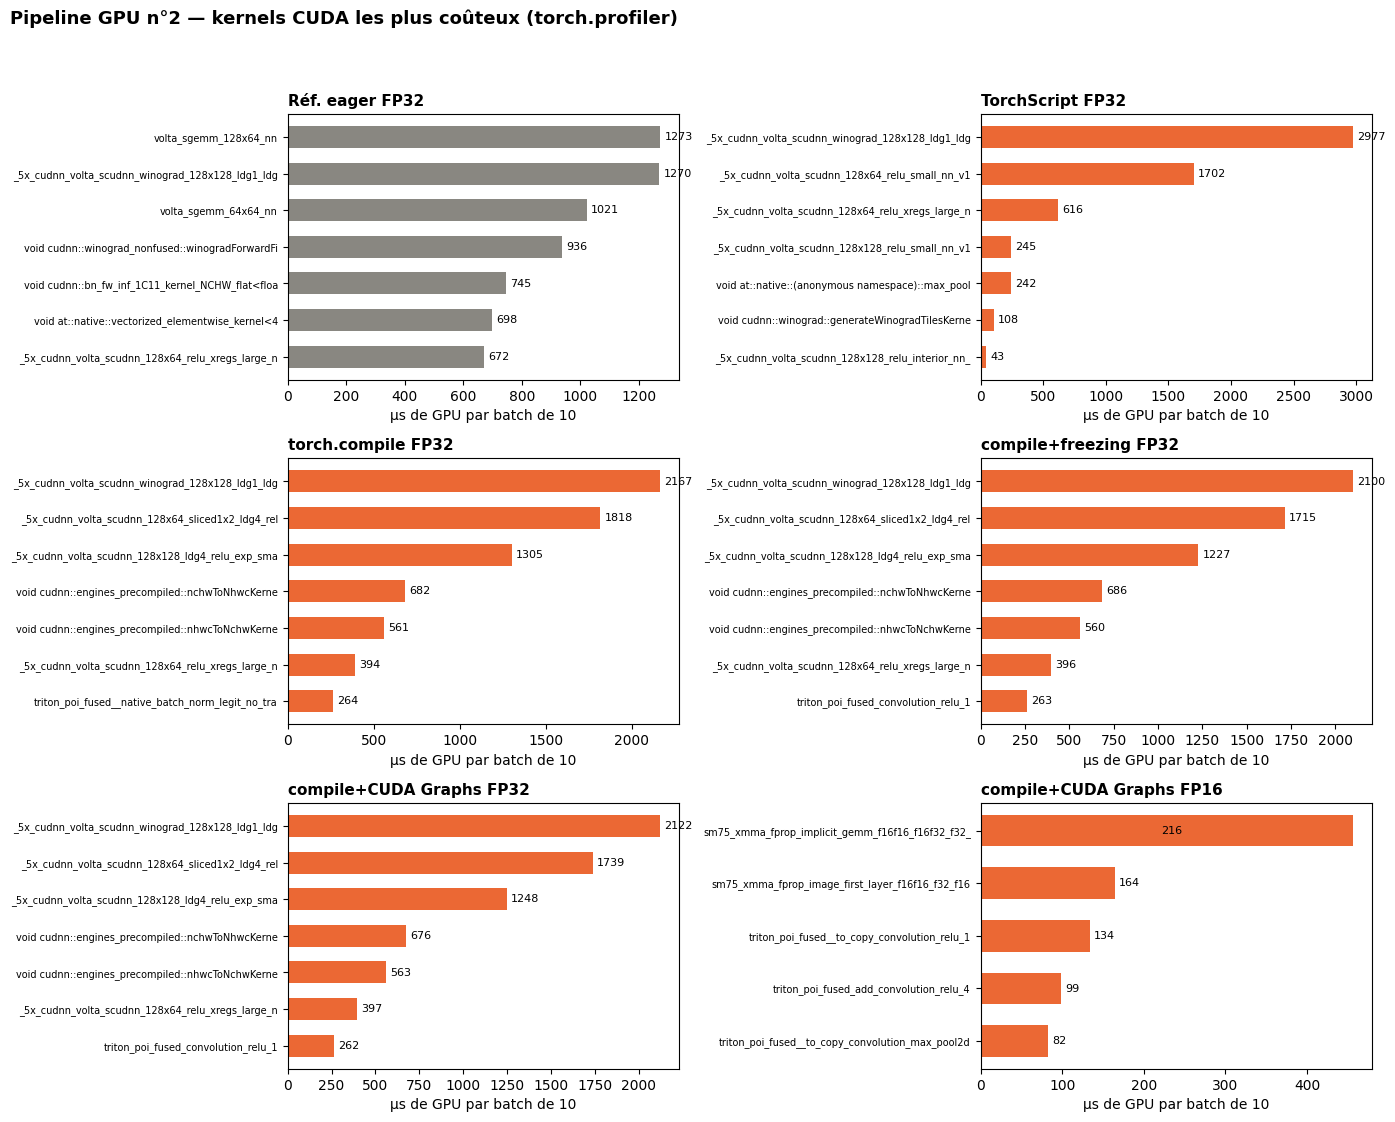


=== Réf. eager FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
18,volta_sgemm_128x64_nn,6.0,1273.1
5,_5x_cudnn_volta_scudnn_winograd_128x128_ldg1_l...,4.0,1269.5
19,volta_sgemm_64x64_nn,3.0,1021.2
15,void cudnn::winograd_nonfused::winogradForward...,9.0,936.1
12,void cudnn::bn_fw_inf_1C11_kernel_NCHW_flat<fl...,15.0,744.8
8,void at::native::vectorized_elementwise_kernel...,17.0,698.1
4,_5x_cudnn_volta_scudnn_128x64_relu_xregs_large...,2.0,672.3
14,void cudnn::winograd_nonfused::winogradForward...,9.0,532.5



=== TorchScript FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
5,_5x_cudnn_volta_scudnn_winograd_128x128_ldg1_l...,10.0,2976.6
3,_5x_cudnn_volta_scudnn_128x64_relu_small_nn_v1,4.0,1702.0
4,_5x_cudnn_volta_scudnn_128x64_relu_xregs_large...,2.0,615.8
1,_5x_cudnn_volta_scudnn_128x128_relu_small_nn_v1,2.0,244.9
6,void at::native::(anonymous namespace)::max_po...,1.0,242.2
11,void cudnn::winograd::generateWinogradTilesKer...,10.0,107.7
0,_5x_cudnn_volta_scudnn_128x128_relu_interior_n...,1.0,43.5
2,_5x_cudnn_volta_scudnn_128x64_relu_interior_nn_v1,1.0,36.4



=== torch.compile FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
7,_5x_cudnn_volta_scudnn_winograd_128x128_ldg1_l...,7.0,2166.9
6,_5x_cudnn_volta_scudnn_128x64_sliced1x2_ldg4_r...,5.0,1818.3
1,_5x_cudnn_volta_scudnn_128x128_ldg4_relu_exp_s...,3.0,1305.1
31,void cudnn::engines_precompiled::nchwToNhwcKer...,8.0,681.8
32,void cudnn::engines_precompiled::nhwcToNchwKer...,16.0,560.8
4,_5x_cudnn_volta_scudnn_128x64_relu_xregs_large...,1.0,394.3
21,triton_poi_fused__native_batch_norm_legit_no_t...,1.0,263.6
16,triton_poi_fused__native_batch_norm_legit_no_t...,3.0,234.8


... (2 outputs left out)


=== compile+CUDA Graphs FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
8,_5x_cudnn_volta_scudnn_winograd_128x128_ldg1_l...,7.0,2121.7
7,_5x_cudnn_volta_scudnn_128x64_sliced1x2_ldg4_r...,5.0,1738.7
2,_5x_cudnn_volta_scudnn_128x128_ldg4_relu_exp_s...,3.0,1247.8
25,void cudnn::engines_precompiled::nchwToNhwcKer...,8.0,675.5
26,void cudnn::engines_precompiled::nhwcToNchwKer...,16.0,562.8
5,_5x_cudnn_volta_scudnn_128x64_relu_xregs_large...,1.0,397.2
18,triton_poi_fused_convolution_relu_1,1.0,262.2
1,_5x_cudnn_volta_scudnn_128x128_ldg4_relu_exp_m...,1.0,217.3



=== compile+CUDA Graphs FP16 ===


,kernel,appels/batch,temps GPU (µs/batch)
5,sm75_xmma_fprop_implicit_gemm_f16f16_f16f32_f3...,6.0,456.4
6,sm75_xmma_fprop_implicit_gemm_f16f16_f16f32_f3...,4.0,382.7
4,sm75_xmma_fprop_implicit_gemm_f16f16_f16f32_f3...,3.0,216.4
3,sm75_xmma_fprop_image_first_layer_f16f16_f32_f...,1.0,164.4
15,triton_poi_fused__to_copy_convolution_relu_1,1.0,134.2
18,triton_poi_fused_add_convolution_relu_4,2.0,98.6
14,triton_poi_fused__to_copy_convolution_max_pool...,1.0,82.3
8,sm75_xmma_fprop_implicit_gemm_f16f16_f16f32_f3...,1.0,58.4


In [21]:
ALL_PROFILES = {"Réf. eager FP32": profile_gpu_kernels(infer_eager_gpu)}
if TS_OK:
    ALL_PROFILES["TorchScript FP32"] = profile_gpu_kernels(infer_ts)
ALL_PROFILES.update(PROFILES)
prof_summary = gpu_profile_report(ALL_PROFILES, "Pipeline GPU n°2 — kernels CUDA les plus coûteux (torch.profiler)",
                                  "ptgpu_profil_kernels.png", {k: ("#898781" if "eager" in k else "#eb6834") for k in ALL_PROFILES})

### 6.1 (Optionnel) Effet de la taille de batch sur GPU
Hors protocole commun : débit et latence pour des batches de 1, 10 et 50 (5 répétitions). Enregistré à part (`results/batch_study/`), **n'entre pas** dans la comparaison des 4 pipelines. Mettre `RUN_BATCH_STUDY = False` pour passer cette étape.

Réf. eager FP32              batch  1 :    291.7 ±  19.8 img/s | latence/batch 3.44 ms
Réf. eager FP32              batch 10 :    892.2 ±   6.2 img/s | latence/batch 11.21 ms
Réf. eager FP32              batch 50 :   1086.3 ±   1.2 img/s | latence/batch 46.02 ms
TorchScript FP32             batch  1 :    473.8 ±   9.2 img/s | latence/batch 2.11 ms
TorchScript FP32             batch 10 :   1070.0 ±   8.1 img/s | latence/batch 9.34 ms
TorchScript FP32             batch 50 :   1379.0 ±   7.5 img/s | latence/batch 36.26 ms
compile+CUDA Graphs FP32     batch  1 :    431.6 ±   1.4 img/s | latence/batch 2.32 ms
compile+CUDA Graphs FP32     batch 10 :    904.3 ±   8.3 img/s | latence/batch 11.06 ms
compile+CUDA Graphs FP32     batch 50 :   1017.3 ±   5.4 img/s | latence/batch 49.15 ms
compile+CUDA Graphs FP16     batch  1 :   1019.0 ±  45.1 img/s | latence/batch 0.98 ms
compile+CUDA Graphs FP16     batch 10 :   2581.2 ±   7.7 img/s | latence/batch 3.87 ms
compile+CUDA Graphs FP16     batch 50 

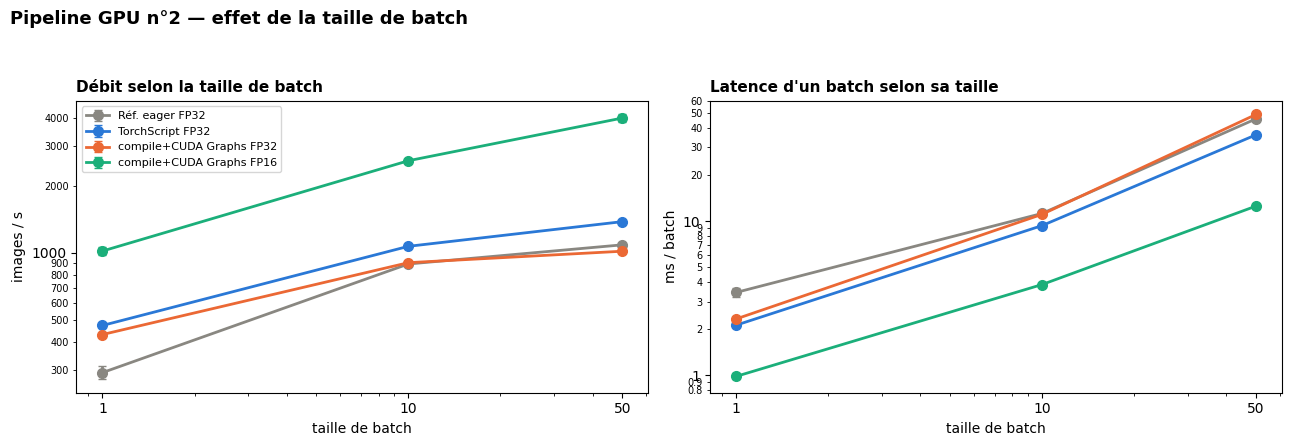

,variante,batch,débit (img/s),débit σ,latence batch (ms),latence σ,Top-1 %
0,Réf. eager FP32,1,291.68,19.78,3.44,0.25,90.0
1,Réf. eager FP32,10,892.22,6.15,11.21,0.08,90.0
2,Réf. eager FP32,50,1086.32,1.18,46.02,0.05,90.0
3,TorchScript FP32,1,473.80,9.16,2.11,0.04,90.0
4,TorchScript FP32,10,1070.01,8.12,9.34,0.07,90.0
5,TorchScript FP32,50,1379.04,7.53,36.26,0.20,90.0
6,compile+CUDA Graphs FP32,1,431.61,1.37,2.32,0.01,90.0
7,compile+CUDA Graphs FP32,10,904.28,8.27,11.06,0.10,90.0
8,compile+CUDA Graphs FP32,50,1017.33,5.44,49.15,0.26,90.0
9,compile+CUDA Graphs FP16,1,1019.04,45.06,0.98,0.04,90.0


In [22]:
# ---------- Étude complémentaire : effet de la taille de batch sur GPU ----------
# Hors protocole commun (batch 10) : ces mesures ne sont PAS enregistrées dans results/*.json
# (la comparaison des 4 pipelines exige le même batch). Elles sont sauvegardées à part.
import matplotlib.ticker

def batch_study(variants, batch_sizes, fname, title):
    rows = []
    for label, make_fn in variants:
        for b in batch_sizes:
            fn = make_fn(b)
            runs, _ = benchmark(fn, X50_GPU, Y50_NP, cuda_sync, batch_size=b, n_runs=5)
            tp = describe([r["throughput_img_s"] for r in runs])
            lat = describe([r["batch_latency_mean_ms"] for r in runs])
            rows.append({"variante": label, "batch": b, "débit (img/s)": tp["mean"], "débit σ": tp["std"],
                         "latence batch (ms)": lat["mean"], "latence σ": lat["std"],
                         "Top-1 %": runs[0]["top1_acc_pct"]})
            print(f"{label:<28} batch {b:>2} : {tp['mean']:8.1f} ± {tp['std']:5.1f} img/s | latence/batch {lat['mean']:.2f} ms")
    df = pd.DataFrame(rows)
    os.makedirs(f"{RESULTS}/batch_study", exist_ok=True)
    df.to_csv(f"{RESULTS}/batch_study/{fname}.csv", index=False)
    pal = ["#898781", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (lab, g) in enumerate(df.groupby("variante", sort=False)):
        axes[0].errorbar(g["batch"], g["débit (img/s)"], yerr=g["débit σ"], marker="o", lw=2, ms=7, capsize=3, color=pal[i % 5], label=lab)
        axes[1].errorbar(g["batch"], g["latence batch (ms)"], yerr=g["latence σ"], marker="o", lw=2, ms=7, capsize=3, color=pal[i % 5], label=lab)
    for ax, yl, t in [(axes[0], "images / s", "Débit selon la taille de batch"),
                      (axes[1], "ms / batch", "Latence d'un batch selon sa taille")]:
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(batch_sizes); ax.set_xticklabels(batch_sizes)
        ax.set_xlabel("taille de batch"); ax.set_ylabel(yl); ax.set_title(t, loc="left", fontsize=11, fontweight="bold")
        fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
        ax.yaxis.set_major_formatter(fmt); ax.yaxis.set_minor_formatter(fmt); ax.tick_params(axis="y", which="minor", labelsize=7)
    axes[0].legend(fontsize=8)
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIGS}/{fname}.png", bbox_inches="tight"); plt.show()
    return df

def lazy_compiled(**kw):
    holder = {}
    def make(b):
        if "f" not in holder:
            holder["f"] = make_compiled(**kw)     # une compilation par forme d'entrée (dynamic=False)
        return holder["f"]
    return make

if RUN_BATCH_STUDY:
    variants = [("Réf. eager FP32", lambda b: infer_eager_gpu)]
    if TS_OK:
        variants.append(("TorchScript FP32", lambda b: infer_ts))
    if "GPU-2 compile+CUDA Graphs FP32" not in FAILED:
        variants.append(("compile+CUDA Graphs FP32", lazy_compiled(freezing=True, mode="reduce-overhead")))
    if RUN_FP16 and "GPU-2 compile+CUDA Graphs FP16" not in FAILED:
        variants.append(("compile+CUDA Graphs FP16", lazy_compiled(freezing=True, mode="reduce-overhead", fp16=True)))
    try:
        df_bs = batch_study(variants, [1, 10, 50], "ptgpu_taille_batch", "Pipeline GPU n°2 — effet de la taille de batch")
        display(df_bs.round(2))
    except Exception as e:
        FAILED["Étude des tailles de batch"] = repr(e)
        print("⚠ Étude des tailles de batch interrompue (sans effet sur les autres résultats) :", repr(e))
    inductor_config.freezing = False

## 5. Résultats du pipeline GPU n°2 (TorchScript / torch.compile) (vs référence de la même session)
Barres d'erreur : **± 1 écart-type** sur les 10 répétitions (3 pour l'énergie). Les fonctions de graphiques sont celles des notebooks CPU (cellule identique).

In [23]:
# ============================================================
# Outils de visualisation et de comparaison — IDENTIQUES dans les deux notebooks
# ============================================================
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
# Une couleur par famille de pipeline (même couleur dans tous les graphiques) ;
# les variantes FP16 sont hachurées pour ne pas reposer sur la couleur seule.
FAMILY_COLORS = {"reference": "#898781", "pipeline1": "#2a78d6", "pipeline2": "#eb6834"}
FAMILY_NAMES = {"reference": "Référence : PyTorch eager",
                "pipeline1": "Pipeline n°1 : ONNX → moteur spécialisé (OpenVINO / TensorRT)",
                "pipeline2": "Pipeline n°2 : compilation PyTorch (TorchScript / torch.compile)"}
HATCHES = {"FP16": "///", "INT8": "xx"}

def load_results(keys=None):
    allres = {}
    for p in sorted(glob.glob(f"{RESULTS}/*.json")):
        with open(p) as f:
            r = json.load(f)
        if "key" in r and "summary" in r:
            allres[r["key"]] = r
    if keys is None:
        return allres
    return {k: allres[k] for k in keys if k in allres}

def _stat(r, name, energy=False):
    if energy:
        if not r.get("energy"):
            return None
        return r["energy"]["summary"].get(name)
    return r["summary"].get(name)

def bar_chart(ax, results, name, ylabel, title, energy=False, log=False, fmt="{:.1f}", baseline=None):
    labels, means, stds, colors, hatches = [], [], [], [], []
    for r in results.values():
        s = _stat(r, name, energy)
        if s is None:
            continue
        labels.append(r["label"]); means.append(s["mean"]); stds.append(s["std"])
        colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
        hatches.append(HATCHES.get(r["precision"], ""))
    if not labels:
        ax.text(0.5, 0.5, "Mesure indisponible", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
        return
    x = np.arange(len(labels))
    bars = ax.bar(x, means, yerr=stds, capsize=4, width=0.62, color=colors,
                  edgecolor="white", linewidth=1.5,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b", "capthick": 1.1})
    for b, h in zip(bars, hatches):
        b.set_hatch(h)
    for xi, m, s in zip(x, means, stds):
        ax.annotate(fmt.format(m), (xi, m + s), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#0b0b0b")
    if baseline is not None:
        ax.axhline(baseline, color="#52514e", linewidth=1, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, max(m + s for m, s in zip(means, stds)) * 1.18)

def add_legend(fig, results):
    fams = []
    for r in results.values():
        if r["family"] not in fams:
            fams.append(r["family"])
    handles = [Patch(facecolor=FAMILY_COLORS[f], label=FAMILY_NAMES[f]) for f in fams]
    for prec, h in HATCHES.items():
        if any(r["precision"] == prec for r in results.values()):
            handles.append(Patch(facecolor="#c3c2b7", hatch=h, edgecolor="white", label=f"Variante {prec}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 4),
               frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)

def fig_performance(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    bar_chart(axes[0, 0], results, "throughput_img_s", "images / s", "Débit (moyenne ± écart-type)", log=log)
    bar_chart(axes[0, 1], results, "batch_latency_mean_ms", "ms / batch",
              f"Latence par batch de {BATCH_SIZE} images", log=log, fmt="{:.2f}")
    bar_chart(axes[1, 0], results, "total_time_ms", "ms", f"Temps d'inférence total ({N_IMAGES} images)",
              log=log, fmt="{:.1f}")
    bar_chart(axes[1, 1], results, "top1_acc_pct", "%", "Précision Top-1 sur les 50 images", fmt="{:.0f}")
    axes[1, 1].set_ylim(0, 105)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_energy(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    bar_chart(axes[0], results, "energy_per_image_mj", "mJ / image", "Énergie par image (brute)",
              energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[1], results, "net_energy_per_image_mj", "mJ / image",
              "Énergie par image (nette, repos déduit)", energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[2], results, "mean_power_w", "W", "Puissance moyenne pendant l'inférence",
              energy=True, fmt="{:.1f}")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_variability(results, suptitle, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
    data, labels, colors = [], [], []
    for r in results.values():
        tp = np.array([run["throughput_img_s"] for run in r["runs"]])
        data.append(100 * tp / np.median(tp))
        labels.append(r["label"]); colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
    bp = axes[0].boxplot(data, patch_artist=True, widths=0.55, showmeans=True, showfliers=False,
                         meanprops={"marker": "D", "markerfacecolor": "#0b0b0b", "markeredgecolor": "white", "markersize": 6},
                         medianprops={"color": "#0b0b0b"})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for i, d in enumerate(data, start=1):
        axes[0].scatter(np.full(len(d), i) + np.random.uniform(-0.12, 0.12, len(d)), d,
                        s=14, color="#0b0b0b", alpha=0.6, zorder=3)
    axes[0].axhline(100, color="#52514e", linewidth=1, linestyle="--")
    axes[0].set_xticks(range(1, len(labels) + 1))
    axes[0].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[0].set_ylabel("% de la médiane")
    axes[0].set_title("Dispersion du débit entre répétitions (normalisé)", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(axis="x", visible=False)
    cv =[r["summary"]["throughput_img_s"]["cv_pct"] for r in results.values()]
    x = np.arange(len(cv))
    axes[1].bar(x, cv, width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, cv):
        axes[1].annotate(f"{v:.1f} %", (xi, v), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].axhline(5, color="#52514e", linewidth=1, linestyle="--")
    axes[1].text(len(cv) - 0.5, 5, " seuil 5 %", va="bottom", ha="right", fontsize=8, color="#52514e")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("CV = écart-type / moyenne (%)")
    axes[1].set_title("Coefficient de variation du débit", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    axes[1].set_ylim(0, max(max(cv) * 1.25, 6))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def _softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def prediction_comparison(results, ref_key):
    logits = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in results}
    keys = list(logits)
    preds = {k: v.argmax(1) for k, v in logits.items()}
    M = np.array([[100 * (preds[a] == preds[b]).mean() for b in keys] for a in keys])
    ref = logits[ref_key]
    pref = _softmax(ref)
    rows = []
    for k, v in logits.items():
        rows.append({"pipeline": results[k]["label"],
                     "accord_top1_vs_ref_%": 100 * (preds[k] == preds[ref_key]).mean(),
                     "max_|Δlogit|": float(np.abs(v - ref).max()),
                     "moy_|Δlogit|": float(np.abs(v - ref).mean()),
                     "max_|Δproba|": float(np.abs(_softmax(v) - pref).max()),
                     "top1_%": 100 * (preds[k] == Y50_NP).mean()})
    return keys, M, pd.DataFrame(rows).set_index("pipeline")

def fig_agreement(results, ref_key, suptitle, fname):
    keys, M, df = prediction_comparison(results, ref_key)
    labels = [results[k]["label"] for k in keys]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
    vmin = min(90, M.min())
    im = axes[0].imshow(M, cmap="Blues", vmin=vmin, vmax=100)
    for i in range(len(keys)):
        for j in range(len(keys)):
            axes[0].text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if M[i, j] > (vmin + 100) / 2 else "#0b0b0b")
    axes[0].set_xticks(range(len(keys))); axes[0].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    axes[0].set_yticks(range(len(keys))); axes[0].set_yticklabels(labels, fontsize=8)
    axes[0].grid(False)
    axes[0].set_title("Accord des prédictions Top-1 entre pipelines (%)", loc="left", fontsize=11, fontweight="bold")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
    d = df["max_|Δlogit|"].values
    colors = [FAMILY_COLORS.get(results[k]["family"], "#898781") for k in keys]
    x = np.arange(len(keys))
    axes[1].bar(x, np.maximum(d, 1e-8), width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, d):
        axes[1].annotate(f"{v:.1e}", (xi, max(v, 1e-8)), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("max |logit − logit_réf| (échelle log)")
    axes[1].set_title(f"Écart numérique vs {results[ref_key]['label']}", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()
    return df

def summary_table(results):
    rows = []
    for r in results.values():
        s = r["summary"]; e = r["energy"]["summary"] if r.get("energy") else None
        row = {
            "pipeline": r["label"], "plateforme": r["platform"], "précision": r["precision"],
            "débit moy (img/s)": s["throughput_img_s"]["mean"], "débit σ": s["throughput_img_s"]["std"],
            "débit min": s["throughput_img_s"]["min"], "débit max": s["throughput_img_s"]["max"],
            "débit CV %": s["throughput_img_s"]["cv_pct"],
            "latence batch moy (ms)": s["batch_latency_mean_ms"]["mean"], "latence σ": s["batch_latency_mean_ms"]["std"],
            "latence min": s["batch_latency_mean_ms"]["min"], "latence max": s["batch_latency_mean_ms"]["max"],
            "temps 50 img moy (ms)": s["total_time_ms"]["mean"], "temps σ": s["total_time_ms"]["std"],
            "temps min": s["total_time_ms"]["min"], "temps max": s["total_time_ms"]["max"],
            "Top-1 moy %": s["top1_acc_pct"]["mean"], "Top-1 σ": s["top1_acc_pct"]["std"],
        }
        if e:
            row.update({"E/image moy (mJ)": e["energy_per_image_mj"]["mean"], "E/image σ": e["energy_per_image_mj"]["std"],
                        "E nette/image (mJ)": e["net_energy_per_image_mj"]["mean"],
                        "puissance moy (W)": e["mean_power_w"]["mean"], "méthode énergie": r["energy"]["method"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline")

def auto_comments(results, ref_key):
    # Génère des constats chiffrés pour aider à rédiger l'analyse (à reformuler dans le rapport).
    ref = results[ref_key]
    tref = ref["summary"]["throughput_img_s"]["mean"]
    print(f"Référence : {ref['label']} = {tref:.1f} img/s\n")
    best = max(results.values(), key=lambda r: r["summary"]["throughput_img_s"]["mean"])
    for r in results.values():
        s = r["summary"]
        tp = s["throughput_img_s"]
        line = (f"- {r['label']:<28} débit {tp['mean']:9.1f} img/s  (×{tp['mean'] / tref:5.2f} vs réf.)"
                f"  CV {tp['cv_pct']:4.1f} %  [{tp['min']:.1f} ; {tp['max']:.1f}]"
                f"  Top-1 {s['top1_acc_pct']['mean']:.0f} %")
        if r.get("energy"):
            line += f"  E/img {r['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
        stab = "stable" if tp["cv_pct"] < 2 else ("assez stable" if tp["cv_pct"] < 5 else "VARIABLE")
        print(line + f"  → {stab}")
    print(f"\nPipeline le plus rapide : {best['label']}")
    accs = {r["label"]: r["summary"]["top1_acc_pct"]["mean"] for r in results.values()}
    if max(accs.values()) - min(accs.values()) == 0:
        print("Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.")
    else:
        print("Écarts de précision Top-1 observés :", {k: f"{v:.0f} %" for k, v in accs.items()})

def session_ref(r):
    k = r.get("session_ref_key") or ("gpu0_eager_fp32" if r["platform"] == "GPU" else None)
    p = f"{RESULTS}/{k}.json" if k else None
    if p and os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    return None

def fig_speedup(results, suptitle, fname):
    # Accélération du débit par rapport à la référence eager de LA MÊME SESSION (même machine) :
    # robuste au fait que chaque notebook Colab tourne sur sa propre machine virtuelle.
    labs, sp, err, cols, hat = [], [], [], [], []
    for r in results.values():
        ref = session_ref(r)
        if ref is None:
            continue
        a, b = r["summary"]["throughput_img_s"], ref["summary"]["throughput_img_s"]
        v = a["mean"] / b["mean"]
        labs.append(r["label"]); sp.append(v)
        err.append(v * np.sqrt((a["std"] / a["mean"]) ** 2 + (b["std"] / b["mean"]) ** 2))
        cols.append(FAMILY_COLORS.get(r["family"], "#898781")); hat.append(HATCHES.get(r["precision"], ""))
    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(labs) + 3), 4.8))
    bars = ax.bar(range(len(sp)), sp, yerr=err, capsize=4, color=cols, edgecolor="white", linewidth=1.5, width=0.62,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b"})
    for b_, h in zip(bars, hat):
        b_.set_hatch(h)
    for i, v in enumerate(sp):
        ax.annotate(f"×{v:.2f}", (i, v + err[i]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel("débit / débit eager de la même session")
    ax.set_title("Accélération par rapport à PyTorch eager FP32 (même machine)", loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(v + e for v, e in zip(sp, err)) * 1.18 if sp else 1)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def history_table():
    # Une ligne par (pipeline, session) : chaque exécution complète d'un notebook = une exécution indépendante.
    rows = []
    for p in sorted(glob.glob(f"{RESULTS}/history/*.json")):
        with open(p) as f:
            r = json.load(f)
        s = r["summary"]
        rows.append({"pipeline": r["label"], "session": r.get("session_id"), "cpu": r["env"].get("cpu"),
                     "débit (img/s)": s["throughput_img_s"]["mean"],
                     "latence batch (ms)": s["batch_latency_mean_ms"]["mean"],
                     "Top-1 %": s["top1_acc_pct"]["mean"]})
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    agg = df.groupby("pipeline").agg(
        sessions=("session", "nunique"),
        débit_moy=("débit (img/s)", "mean"), débit_σ_inter_sessions=("débit (img/s)", "std"),
        débit_min=("débit (img/s)", "min"), débit_max=("débit (img/s)", "max"),
        latence_moy=("latence batch (ms)", "mean"), latence_σ_inter_sessions=("latence batch (ms)", "std"),
        top1_moy=("Top-1 %", "mean"))
    agg["débit_CV_inter_%"] = 100 * agg["débit_σ_inter_sessions"] / agg["débit_moy"]
    return df, agg

print("Outils de visualisation prêts.")

Outils de visualisation prêts.


In [24]:
PTG_KEYS = ["gpu_pt_ref_eager", "gpu2_torchscript_fp32", "gpu2_compile_fp32", "gpu2_compile_freezing_fp32",
            "gpu2_compile_cudagraphs_fp32", "gpu2_compile_fp16", "gpu2_compile_autotune_fp32"]
ptg_results = load_results(PTG_KEYS)
df_ptg = summary_table(ptg_results)
df_ptg.to_csv(f"{RESULTS}/summary_pipeline_pytorch_gpu.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_ptg

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session PT-GPU),GPU,FP32,980.15,34.82,882.41,1002.44,3.55,10.21,0.40,9.97,11.33,51.08,1.98,49.88,56.66,90.0,0.0,71.86,1.52,42.65,68.58,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 TorchScript FP32,GPU,FP32,1152.46,9.05,1141.27,1164.82,0.78,8.68,0.07,8.58,8.76,43.39,0.34,42.93,43.81,90.0,0.0,60.55,0.55,35.58,67.60,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 torch.compile FP32,GPU,FP32,880.47,8.52,862.59,889.40,0.97,11.36,0.11,11.24,11.59,56.79,0.55,56.22,57.97,90.0,0.0,78.57,0.77,45.95,67.14,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+freezing FP32,GPU,FP32,881.83,5.91,876.85,890.67,0.67,11.34,0.08,11.23,11.40,56.70,0.38,56.14,57.02,90.0,0.0,75.79,0.33,44.16,66.78,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+CUDA Graphs FP32,GPU,FP32,902.36,5.97,894.42,913.14,0.66,11.08,0.07,10.95,11.18,55.41,0.37,54.76,55.90,90.0,0.0,75.92,1.17,44.36,67.06,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+CUDA Graphs FP16,GPU,FP16,2922.65,662.50,2164.01,3587.12,22.67,3.60,0.86,2.79,4.62,17.98,4.31,13.94,23.11,90.0,0.0,20.04,0.46,11.72,67.16,NVML : compteur d'énergie de la carte GPU (mes...


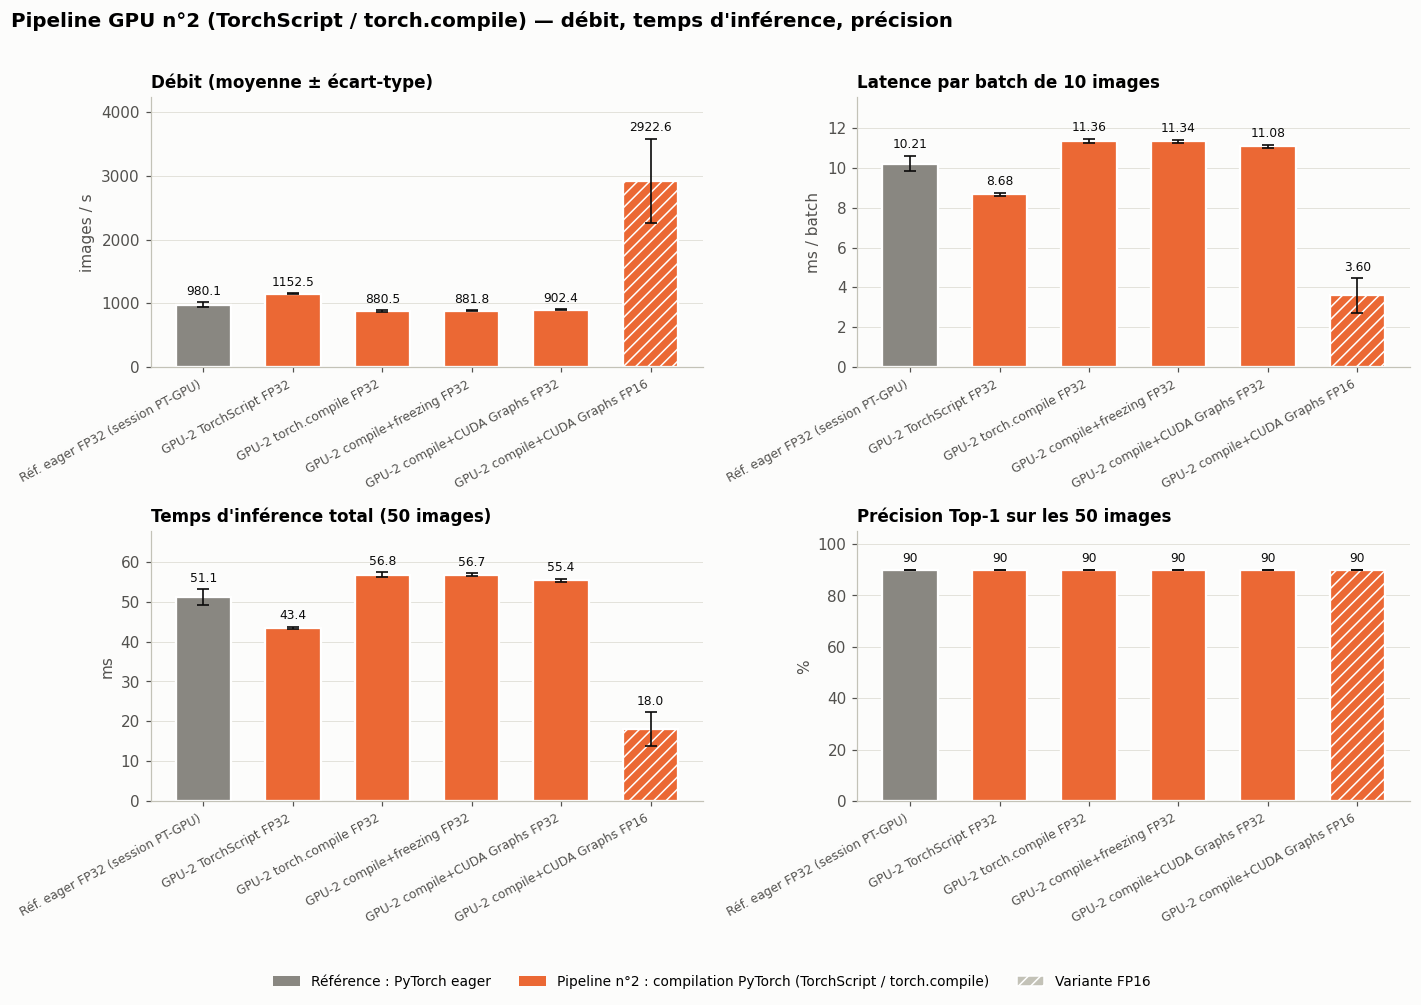

In [25]:
fig_performance(ptg_results, "Pipeline GPU n°2 (TorchScript / torch.compile) — débit, temps d'inférence, précision", "ptg_performance.png")

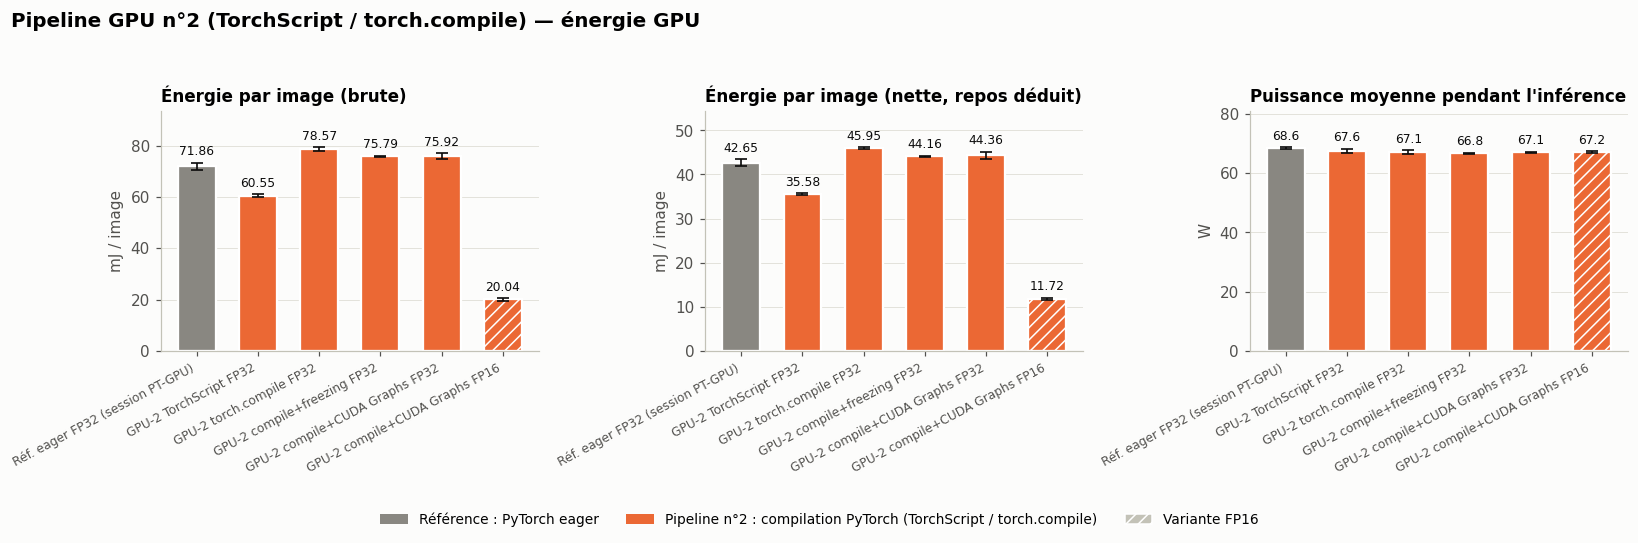

In [26]:
fig_energy(ptg_results, "Pipeline GPU n°2 (TorchScript / torch.compile) — énergie GPU", "ptg_energie.png")

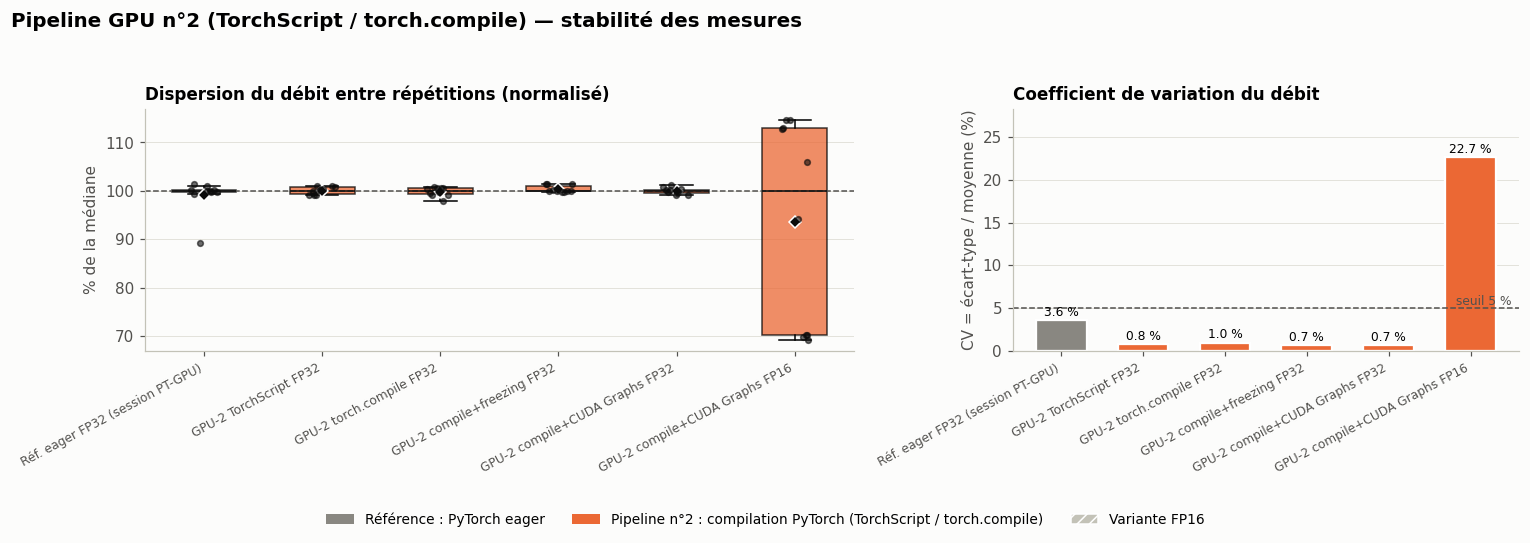

In [27]:
fig_variability(ptg_results, "Pipeline GPU n°2 (TorchScript / torch.compile) — stabilité des mesures", "ptg_variabilite.png")

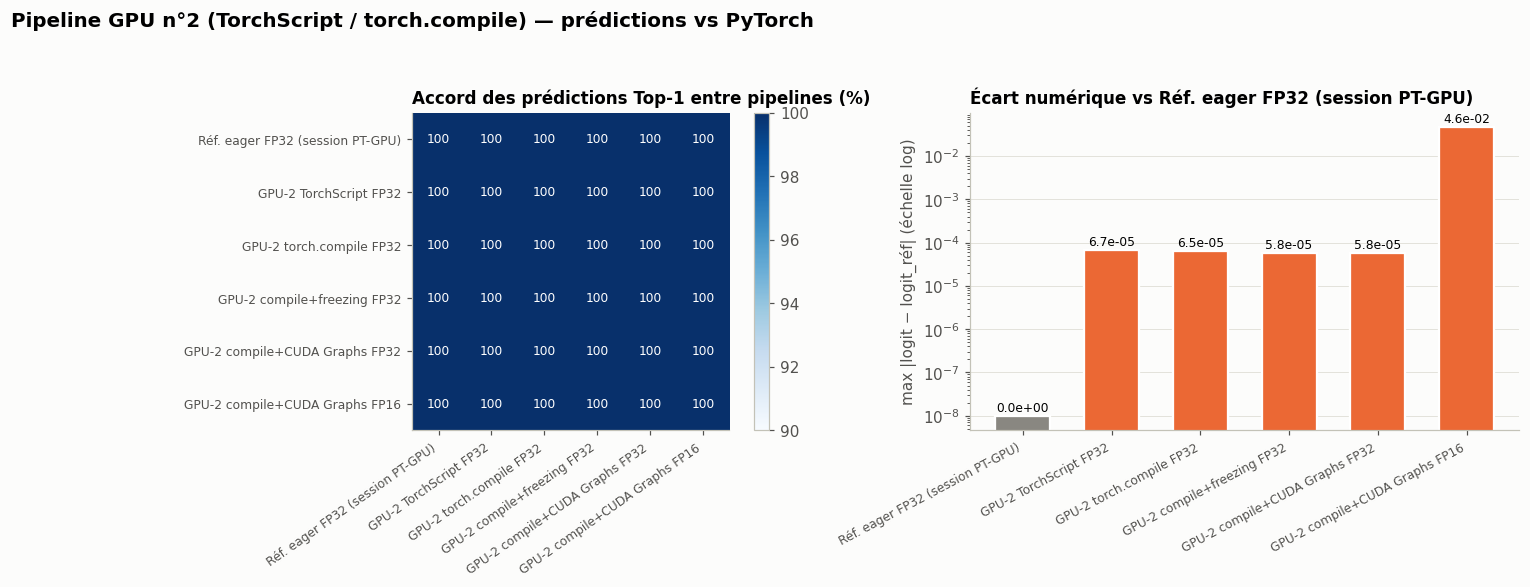

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session PT-GPU),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
GPU-2 TorchScript FP32,100.0,6.68e-05,9.70e-06,6.44e-06,90.0
GPU-2 torch.compile FP32,100.0,6.53e-05,9.47e-06,7.21e-06,90.0
GPU-2 compile+freezing FP32,100.0,5.82e-05,9.67e-06,8.82e-06,90.0
GPU-2 compile+CUDA Graphs FP32,100.0,5.82e-05,9.67e-06,8.82e-06,90.0
GPU-2 compile+CUDA Graphs FP16,100.0,4.62e-02,1.10e-02,6.12e-03,90.0


In [28]:
df_agree_ptg = fig_agreement(ptg_results, SESSION_REF_KEY, "Pipeline GPU n°2 (TorchScript / torch.compile) — prédictions vs PyTorch",
                            "ptg_predictions.png")
df_agree_ptg

In [29]:
auto_comments(ptg_results, SESSION_REF_KEY)

Référence : Réf. eager FP32 (session PT-GPU) = 980.1 img/s

- Réf. eager FP32 (session PT-GPU) débit     980.1 img/s  (× 1.00 vs réf.)  CV  3.6 %  [882.4 ; 1002.4]  Top-1 90 %  E/img 71.86 mJ  → assez stable
- GPU-2 TorchScript FP32       débit    1152.5 img/s  (× 1.18 vs réf.)  CV  0.8 %  [1141.3 ; 1164.8]  Top-1 90 %  E/img 60.55 mJ  → stable
- GPU-2 torch.compile FP32     débit     880.5 img/s  (× 0.90 vs réf.)  CV  1.0 %  [862.6 ; 889.4]  Top-1 90 %  E/img 78.57 mJ  → stable
- GPU-2 compile+freezing FP32  débit     881.8 img/s  (× 0.90 vs réf.)  CV  0.7 %  [876.8 ; 890.7]  Top-1 90 %  E/img 75.79 mJ  → stable
- GPU-2 compile+CUDA Graphs FP32 débit     902.4 img/s  (× 0.92 vs réf.)  CV  0.7 %  [894.4 ; 913.1]  Top-1 90 %  E/img 75.92 mJ  → stable
- GPU-2 compile+CUDA Graphs FP16 débit    2922.6 img/s  (× 2.98 vs réf.)  CV 22.7 %  [2164.0 ; 3587.1]  Top-1 90 %  E/img 20.04 mJ  → VARIABLE

Pipeline le plus rapide : GPU-2 compile+CUDA Graphs FP16
Précision Top-1 identique pour tous les

## 6. Comparaison des pipelines (section identique dans les 4 notebooks)

Cette section recharge **tous les résultats présents dans le dossier `results`** du Drive partagé : ceux des notebooks CPU (OpenVINO, TorchScript / torch.compile) et ceux des notebooks GPU (TensorRT, TorchScript / torch.compile). **Exécutez-la à la fin du dernier notebook lancé** pour obtenir la comparaison complète des 4 pipelines ; elle fonctionne aussi avec un seul pipeline disponible.

Chaque notebook Colab tourne sur **sa propre machine virtuelle** : on vérifie donc que les entrées et le batch sont identiques, et on présente l'**accélération par rapport à la référence eager mesurée dans la même session** (CPU → eager CPU, GPU → eager GPU). Les graphiques sont en échelle logarithmique dès qu'un résultat GPU est présent (écart d'un ou deux ordres de grandeur avec le CPU).

### Importer les résultats des notebooks CPU (envoyés par votre binôme)
Les notebooks CPU enregistrent leurs résultats dans leur propre dossier `results` (fichiers `*.json` et `*_logits.npy`, sous-dossier `history`). Demandez à votre binôme de vous envoyer ce dossier (zip, ou les fichiers), mettez `IMPORT_PARTNER_RESULTS = True` et sélectionnez-le : les fichiers sont copiés dans votre dossier `results`, puis la comparaison ci-dessous inclut les 4 pipelines. Sans import, elle compare seulement les pipelines GPU disponibles.

In [30]:
IMPORT_PARTNER_RESULTS = False
if IMPORT_PARTNER_RESULTS:
    import zipfile, io
    from google.colab import files

    def _store(relname, data):
        relname = relname.replace(chr(92), "/")
        base = os.path.basename(relname).split(" (")[0]
        if "shared/" in relname or "figures/" in relname or not (base.endswith(".json") or base.endswith("_logits.npy")):
            return
        dest = f"{RESULTS}/history/{base}" if "/history/" in "/" + relname or "__" in base else f"{RESULTS}/{base}"
        os.makedirs(os.path.dirname(dest), exist_ok=True)
        with open(dest, "wb") as f:
            f.write(data)
        print("  →", dest.replace(RESULTS, "results"))

    for name, data in files.upload().items():
        if name.endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                for member in z.namelist():
                    if not member.endswith("/"):
                        _store(member, z.read(member))
        else:
            _store(name, data)

In [31]:
CPU_KEYS = ["cpu_ov_ref_eager", "cpu1_openvino_fp32", "cpu1_openvino_int8",
            "cpu_pt_ref_eager", "cpu2_torchscript_fp32", "cpu2_compile_fp32", "cpu2_compile_freezing_fp32",
            "cpu2_compile_autotune_fp32"]
GPU_KEYS = ["gpu_trt_ref_eager", "gpu1_trt_fp32", "gpu1_trt_fp16",
            "gpu_pt_ref_eager", "gpu2_torchscript_fp32", "gpu2_compile_fp32", "gpu2_compile_freezing_fp32",
            "gpu2_compile_cudagraphs_fp32", "gpu2_compile_fp16", "gpu2_compile_autotune_fp32"]
REF_KEYS = ["cpu_ov_ref_eager", "cpu_pt_ref_eager", "gpu_trt_ref_eager", "gpu_pt_ref_eager"]

all_results = load_results(CPU_KEYS + GPU_KEYS)
cpu_all = {k: v for k, v in all_results.items() if v["platform"] == "CPU"}
has_gpu = any(v["platform"] == "GPU" for v in all_results.values())
REF_KEY = next(k for k in REF_KEYS if k in all_results)

if "cpu1_openvino_fp32" not in all_results:
    print("ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "cpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "gpu1_trt_fp32" not in all_results:
    print("ℹ Pipeline GPU n°1 (TensorRT) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "gpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline GPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")

cond = pd.DataFrame([{"pipeline": r["label"], "session": r.get("session_id"), "images": r["n_images"],
                      "batch": r["batch_size"], "warm-up": r["n_warmup"], "répétitions": r["n_runs"],
                      "SHA-256 entrées": r["test_sha256"][:12], "processeur": r["env"].get("cpu"),
                      "vCPU": r["env"].get("n_vcpu"), "GPU": r["env"].get("gpu", "—")}
                     for r in all_results.values()]).set_index("pipeline")
assert cond["batch"].nunique() == 1 and cond["images"].nunique() == 1, "Batch ou nombre d'images différent !"
if cond["SHA-256 entrées"].nunique() == 1:
    print("✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.")
else:
    # Les notebooks ont été exécutés séparément : chacun a recréé les 50 images avec le même code.
    # Les indices sont tirés avec la même graine ; seule l'interpolation flottante peut différer au dernier bit.
    idx = {tuple(r.get("extra", {}).get("test_indices", [])) for r in all_results.values() if r.get("extra", {}).get("test_indices")}
    print("⚠ Empreintes des entrées différentes :", dict(cond["SHA-256 entrées"].value_counts()))
    if len(idx) == 1:
        print("  Indices CIFAR-10 enregistrés par les notebooks GPU :", list(next(iter(idx))))
    print("  → comparez ces indices à ceux affichés en section 1 des notebooks CPU : s'ils sont identiques,"
          " ce sont les mêmes images (seul l'arrondi flottant du redimensionnement diffère).")
w = {r.get("extra", {}).get("weights_sha256", "")[:12] for r in all_results.values() if r.get("extra", {}).get("weights_sha256")}
if len(w) > 1:
    print("ℹ Poids recréés séparément (empreintes différentes) : les têtes 10 classes peuvent différer légèrement,"
          " d'où d'éventuels écarts de prédiction entre plateformes. Pour un modèle strictement identique,"
          " utilisez le même fichier resnet18_cifar10.pth partout (voir section 0).")
cpu_models = {r["env"].get("cpu") for r in cpu_all.values()}
if len(cpu_models) > 1:
    print("⚠ Les sessions CPU n'ont pas eu le même processeur :", cpu_models,
          "\n  → comparez surtout l'accélération vs eager de la même session, ou relancez pour obtenir le même CPU.")
gpu_models = {r["env"].get("gpu") for r in all_results.values() if r["platform"] == "GPU"}
if len(gpu_models) > 1:
    print("⚠ Les sessions GPU n'ont pas eu le même GPU :", gpu_models, "→ relancez avec le même type de GPU (T4).")
cond

ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.
ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.
✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.


,session,images,batch,warm-up,répétitions,SHA-256 entrées,processeur,vCPU,GPU
pipeline,,,,,,,,,
Réf. eager FP32 (session TRT),trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-1 TensorRT FP32,trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-1 TensorRT FP16,trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
Réf. eager FP32 (session PT-GPU),ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-2 TorchScript FP32,ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-2 torch.compile FP32,ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-2 compile+freezing FP32,ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-2 compile+CUDA Graphs FP32,ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-2 compile+CUDA Graphs FP16,ptgpu_20261125-172615,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4


In [32]:
df_all = summary_table(all_results)
df_all.to_csv(f"{RESULTS}/summary_all.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_all

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session TRT),GPU,FP32,1020.38,6.11,1009.09,1028.96,0.60,9.80,0.06,9.72,9.91,49.00,0.29,48.59,49.55,90.0,0.0,69.01,0.49,42.69,68.31,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP32,GPU,FP32,1235.41,15.48,1213.28,1258.61,1.25,8.09,0.10,7.94,8.24,40.48,0.51,39.73,41.21,90.0,0.0,55.80,0.75,34.04,66.83,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP16,GPU,FP16,4272.19,111.20,4069.50,4402.47,2.60,2.34,0.06,2.27,2.46,11.71,0.31,11.36,12.29,90.0,0.0,15.88,0.21,9.66,66.55,NVML : compteur d'énergie de la carte GPU (mes...
Réf. eager FP32 (session PT-GPU),GPU,FP32,980.15,34.82,882.41,1002.44,3.55,10.21,0.40,9.97,11.33,51.08,1.98,49.88,56.66,90.0,0.0,71.86,1.52,42.65,68.58,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 TorchScript FP32,GPU,FP32,1152.46,9.05,1141.27,1164.82,0.78,8.68,0.07,8.58,8.76,43.39,0.34,42.93,43.81,90.0,0.0,60.55,0.55,35.58,67.60,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 torch.compile FP32,GPU,FP32,880.47,8.52,862.59,889.40,0.97,11.36,0.11,11.24,11.59,56.79,0.55,56.22,57.97,90.0,0.0,78.57,0.77,45.95,67.14,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+freezing FP32,GPU,FP32,881.83,5.91,876.85,890.67,0.67,11.34,0.08,11.23,11.40,56.70,0.38,56.14,57.02,90.0,0.0,75.79,0.33,44.16,66.78,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+CUDA Graphs FP32,GPU,FP32,902.36,5.97,894.42,913.14,0.66,11.08,0.07,10.95,11.18,55.41,0.37,54.76,55.90,90.0,0.0,75.92,1.17,44.36,67.06,NVML : compteur d'énergie de la carte GPU (mes...
GPU-2 compile+CUDA Graphs FP16,GPU,FP16,2922.65,662.50,2164.01,3587.12,22.67,3.60,0.86,2.79,4.62,17.98,4.31,13.94,23.11,90.0,0.0,20.04,0.46,11.72,67.16,NVML : compteur d'énergie de la carte GPU (mes...


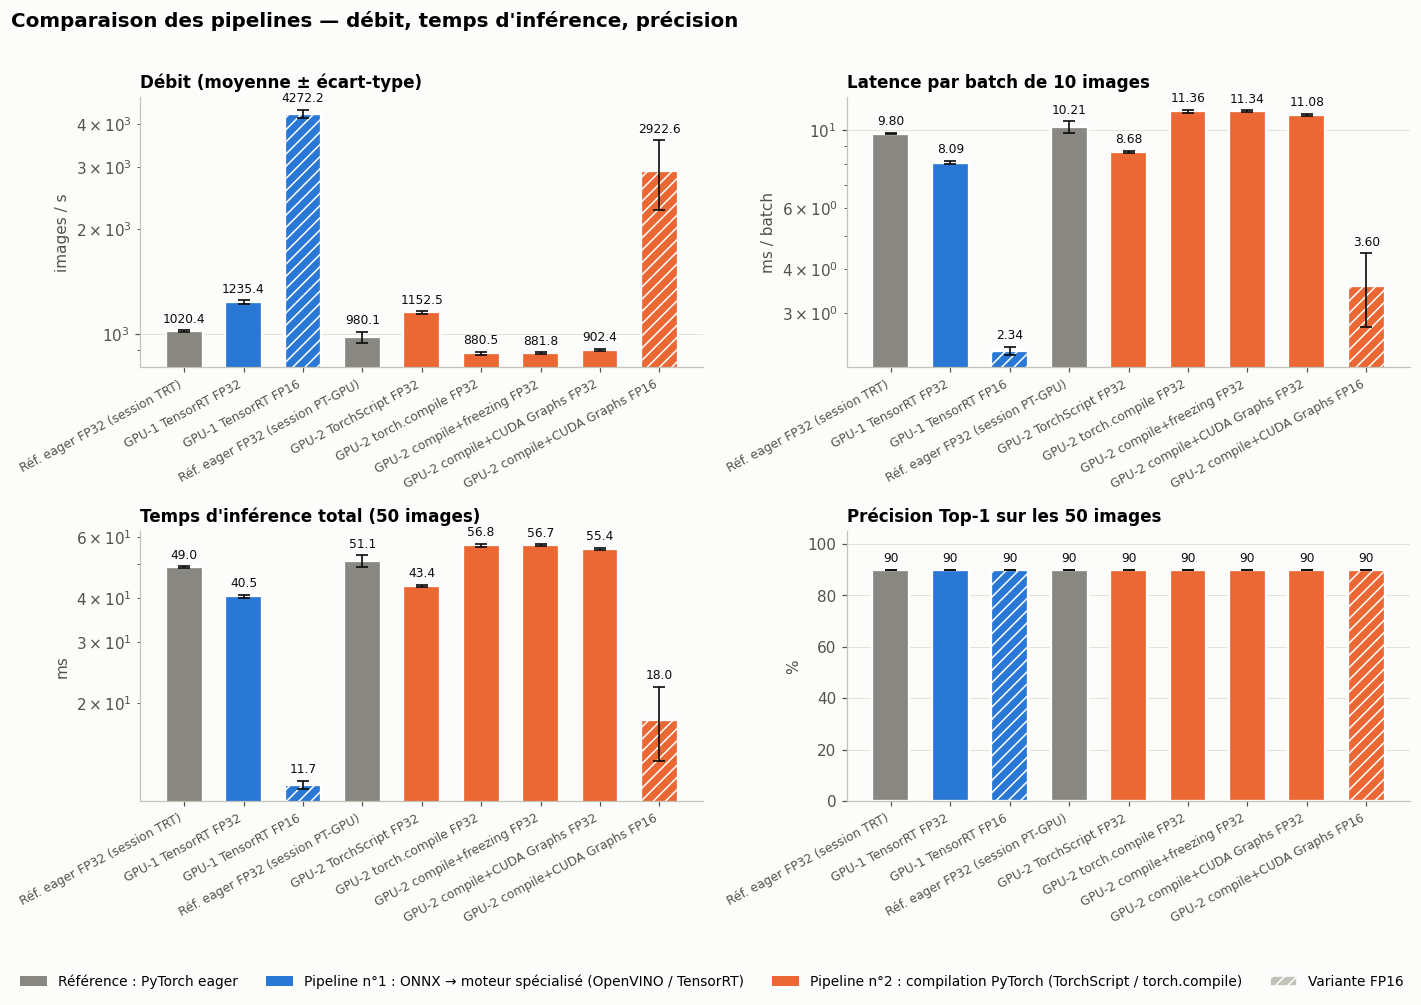

In [33]:
fig_performance(all_results, "Comparaison des pipelines — débit, temps d'inférence, précision",
                "compare_performance.png", log=has_gpu)

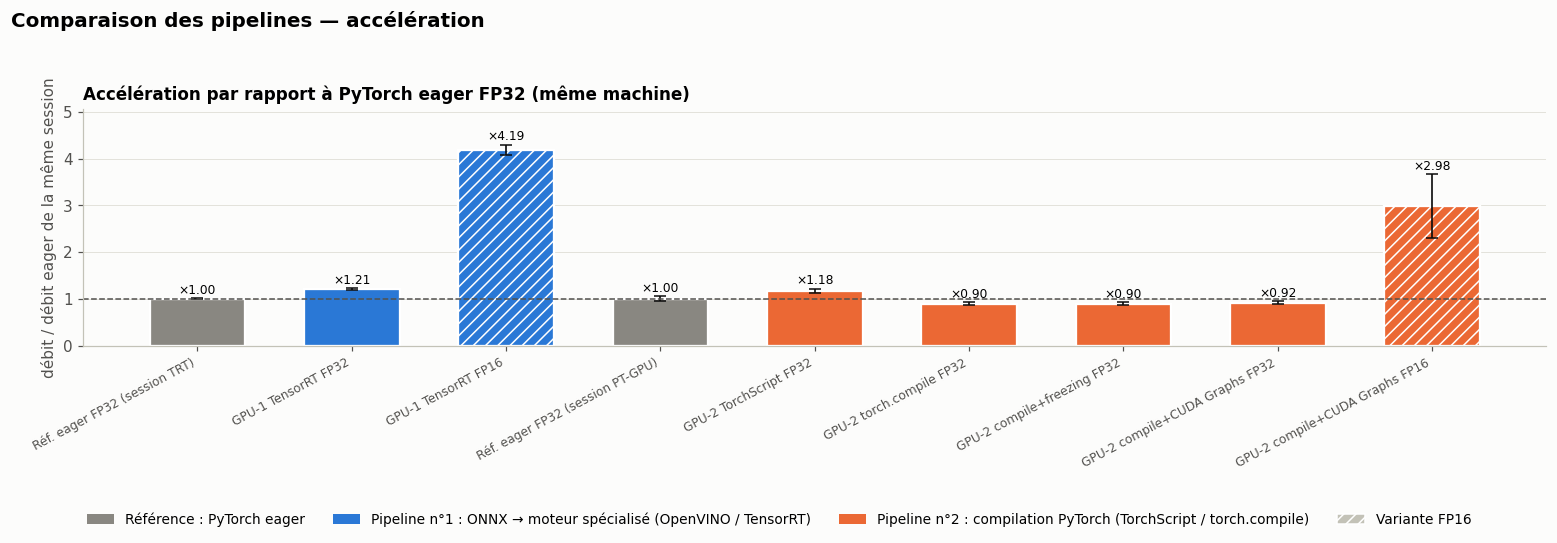

In [34]:
fig_speedup(all_results, "Comparaison des pipelines — accélération", "compare_acceleration.png")

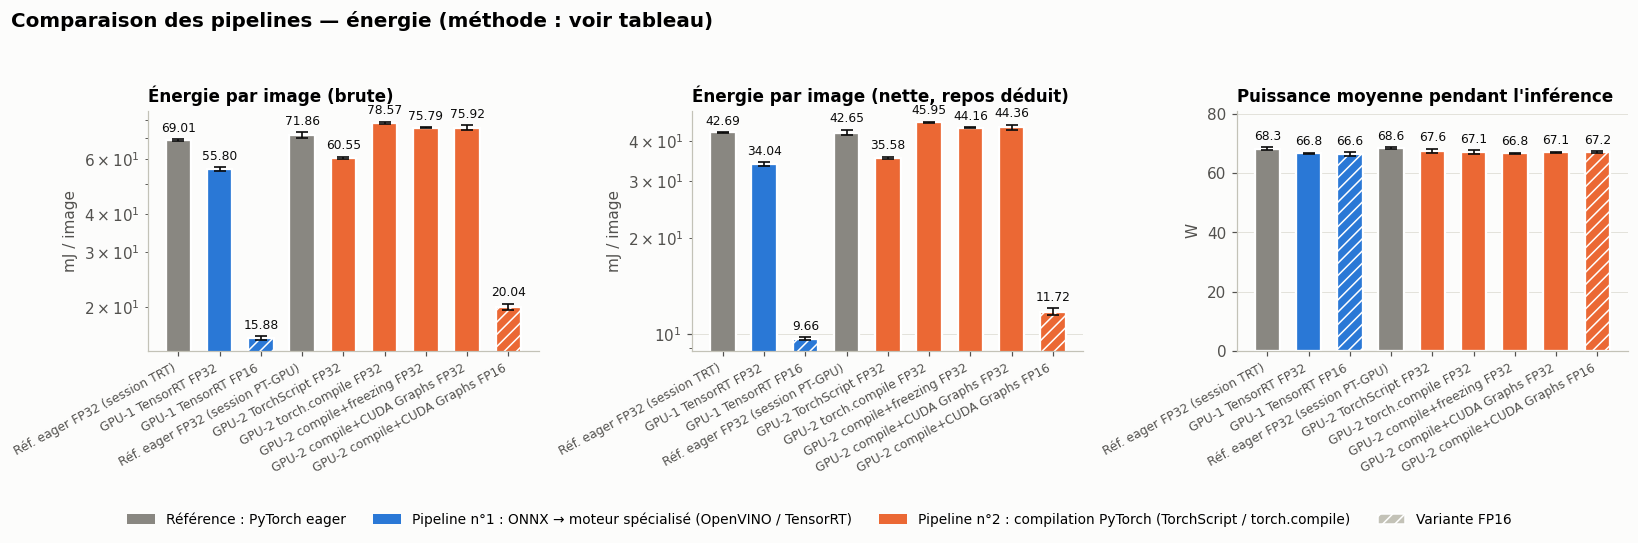

In [35]:
fig_energy(all_results, "Comparaison des pipelines — énergie (méthode : voir tableau)", "compare_energie.png", log=has_gpu)

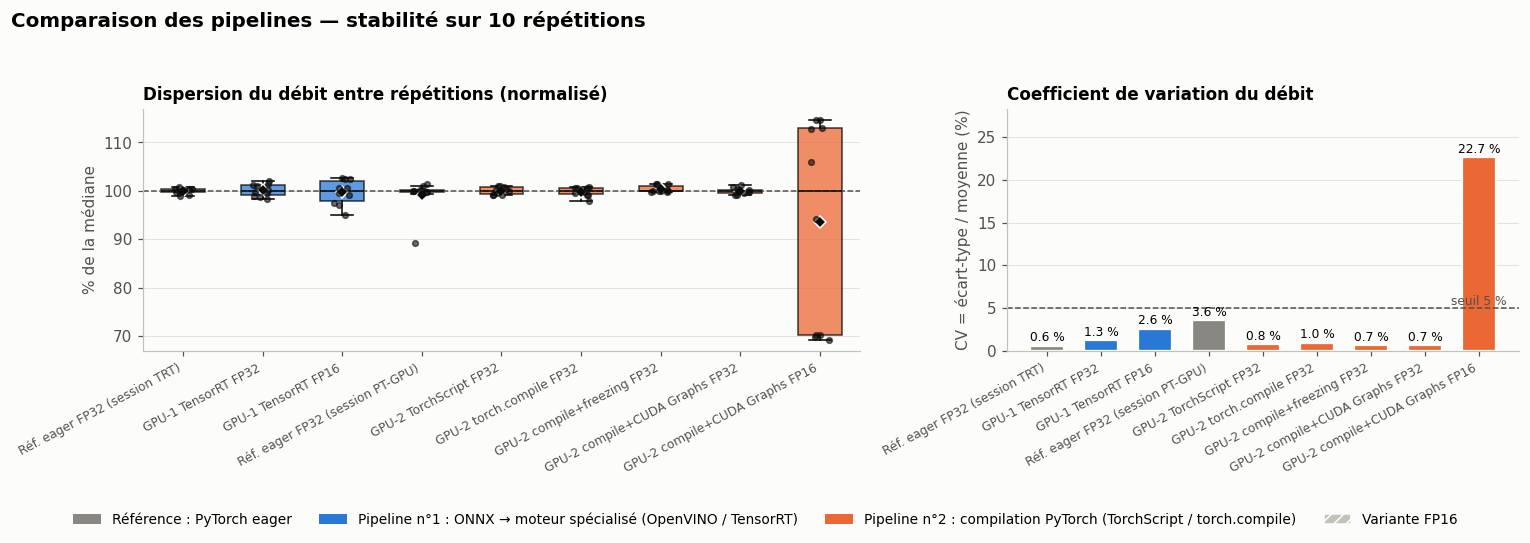

In [36]:
fig_variability(all_results, "Comparaison des pipelines — stabilité sur 10 répétitions", "compare_variabilite.png")

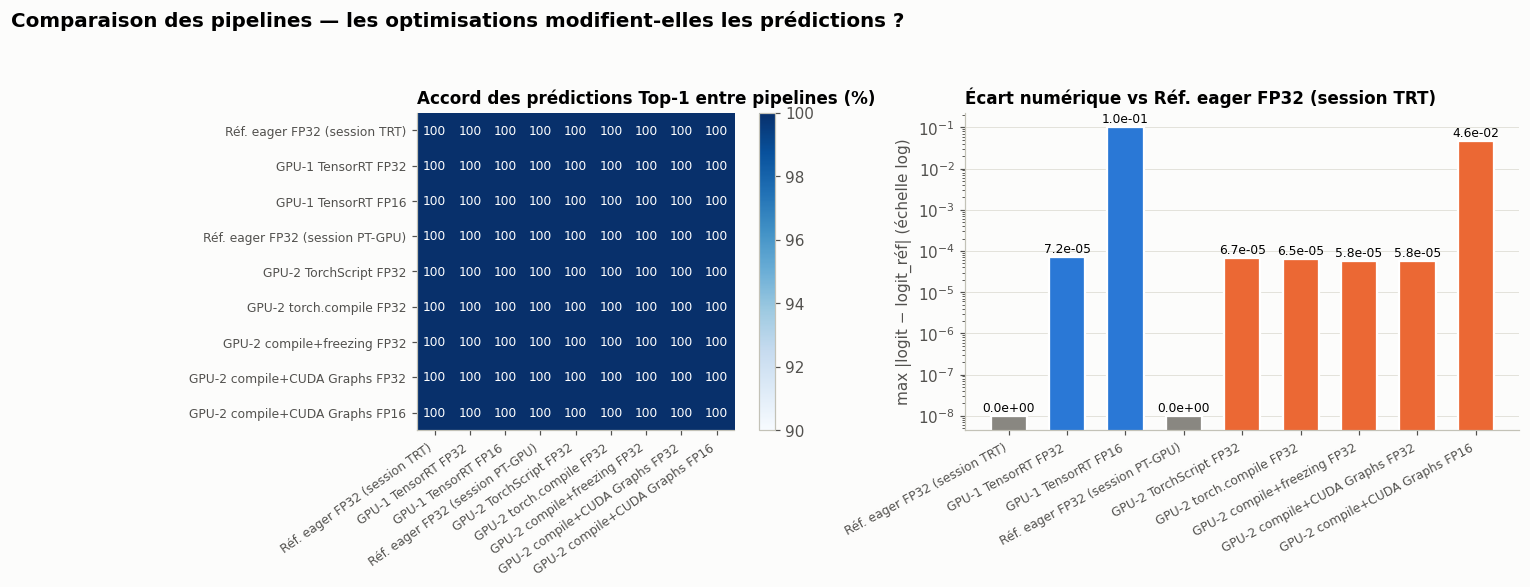

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session TRT),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
GPU-1 TensorRT FP32,100.0,7.25e-05,9.58e-06,6.62e-06,90.0
GPU-1 TensorRT FP16,100.0,1.01e-01,2.11e-02,1.09e-02,90.0
Réf. eager FP32 (session PT-GPU),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
GPU-2 TorchScript FP32,100.0,6.68e-05,9.70e-06,6.44e-06,90.0
GPU-2 torch.compile FP32,100.0,6.53e-05,9.47e-06,7.21e-06,90.0
GPU-2 compile+freezing FP32,100.0,5.82e-05,9.67e-06,8.82e-06,90.0
GPU-2 compile+CUDA Graphs FP32,100.0,5.82e-05,9.67e-06,8.82e-06,90.0
GPU-2 compile+CUDA Graphs FP16,100.0,4.62e-02,1.10e-02,6.12e-03,90.0


In [37]:
df_agree = fig_agreement(all_results, REF_KEY, "Comparaison des pipelines — les optimisations modifient-elles les prédictions ?",
                         "compare_predictions.png")
df_agree

In [38]:
# Images dont la prédiction diffère entre pipelines
logits_all = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in all_results}
ref_pred = logits_all[REF_KEY].argmax(1)
diff_idx = sorted({int(i) for v in logits_all.values() for i in np.where(v.argmax(1) != ref_pred)[0]})
if not diff_idx:
    print("Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.")
else:
    rows = []
    for i in diff_idx:
        row = {"image": i, "vraie classe": CLASSES[Y50_NP[i]]}
        row.update({all_results[k]["label"]: CLASSES[int(v[i].argmax())] for k, v in logits_all.items()})
        rows.append(row)
    display(pd.DataFrame(rows).set_index("image"))

Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.


### Exécutions indépendantes (variabilité entre sessions)
Les 10 répétitions d'un même notebook ont lieu dans **une même session** (même machine, même processus). Pour mesurer la reproductibilité **entre exécutions indépendantes**, relancez chaque notebook dans une **nouvelle session** (`Exécution` → `Déconnecter et supprimer l'environnement d'exécution`, puis `Tout exécuter`) au moins **3 fois**. Chaque exécution ajoute une ligne par pipeline dans `results/history/`, et le tableau ci-dessous calcule moyenne, écart-type, min et max **entre sessions**.

In [39]:
hist_rows, hist_agg = history_table()
if hist_rows.empty:
    print("Aucun historique.")
else:
    display(hist_rows)
    display(hist_agg)
    hist_agg.to_csv(f"{RESULTS}/summary_inter_sessions.csv")
    multi = hist_agg[hist_agg["sessions"] >= 2]
    if len(multi):
        fig, ax = plt.subplots(figsize=(11, 4.5))
        for i, (lab, g) in enumerate(hist_rows.groupby("pipeline")):
            ax.scatter(np.full(len(g), i), g["débit (img/s)"], s=30, color="#2a78d6", zorder=3)
            ax.errorbar(i, g["débit (img/s)"].mean(), yerr=g["débit (img/s)"].std() if len(g) > 1 else 0,
                        fmt="D", color="#0b0b0b", capsize=5)
        ax.set_xticks(range(hist_rows["pipeline"].nunique()))
        ax.set_xticklabels(sorted(hist_rows["pipeline"].unique()), rotation=28, ha="right", fontsize=8)
        ax.set_ylabel("débit moyen de la session (img/s)")
        ax.set_title("Débit par session (points) et moyenne ± écart-type entre sessions", loc="left",
                     fontsize=11, fontweight="bold")
        ax.grid(axis="x", visible=False)
        fig.tight_layout(); fig.savefig(f"{FIGS}/inter_sessions.png", bbox_inches="tight"); plt.show()
    else:
        print("Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.")

,pipeline,session,cpu,débit (img/s),latence batch (ms),Top-1 %
0,GPU-1 TensorRT FP16,trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,4272.19,2.34,90.0
1,GPU-1 TensorRT FP32,trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,1235.41,8.09,90.0
2,GPU-2 compile+CUDA Graphs FP32,ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,902.36,11.08,90.0
3,GPU-2 compile+CUDA Graphs FP16,ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,2922.65,3.60,90.0
4,GPU-2 torch.compile FP32,ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,880.47,11.36,90.0
5,GPU-2 compile+freezing FP32,ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,881.83,11.34,90.0
6,GPU-2 TorchScript FP32,ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,1152.46,8.68,90.0
7,Réf. eager FP32 (session PT-GPU),ptgpu_20261125-172615,Intel(R) Xeon(R) CPU @ 2.00GHz,980.15,10.21,90.0
8,Réf. eager FP32 (session TRT),trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,1020.38,9.80,90.0


,sessions,débit_moy,débit_σ_inter_sessions,débit_min,débit_max,latence_moy,latence_σ_inter_sessions,top1_moy,débit_CV_inter_%
pipeline,,,,,,,,,
GPU-1 TensorRT FP16,1,4272.19,NaN,4272.19,4272.19,2.34,NaN,90.0,NaN
GPU-1 TensorRT FP32,1,1235.41,NaN,1235.41,1235.41,8.09,NaN,90.0,NaN
GPU-2 TorchScript FP32,1,1152.46,NaN,1152.46,1152.46,8.68,NaN,90.0,NaN
GPU-2 compile+CUDA Graphs FP16,1,2922.65,NaN,2922.65,2922.65,3.60,NaN,90.0,NaN
GPU-2 compile+CUDA Graphs FP32,1,902.36,NaN,902.36,902.36,11.08,NaN,90.0,NaN
GPU-2 compile+freezing FP32,1,881.83,NaN,881.83,881.83,11.34,NaN,90.0,NaN
GPU-2 torch.compile FP32,1,880.47,NaN,880.47,880.47,11.36,NaN,90.0,NaN
Réf. eager FP32 (session PT-GPU),1,980.15,NaN,980.15,980.15,10.21,NaN,90.0,NaN
Réf. eager FP32 (session TRT),1,1020.38,NaN,1020.38,1020.38,9.80,NaN,90.0,NaN


Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.


In [40]:
auto_comments(all_results, REF_KEY)
print("\nFigures :", FIGS, "\nTableaux :", f"{RESULTS}/summary_all.csv")

Référence : Réf. eager FP32 (session TRT) = 1020.4 img/s

- Réf. eager FP32 (session TRT) débit    1020.4 img/s  (× 1.00 vs réf.)  CV  0.6 %  [1009.1 ; 1029.0]  Top-1 90 %  E/img 69.01 mJ  → stable
- GPU-1 TensorRT FP32          débit    1235.4 img/s  (× 1.21 vs réf.)  CV  1.3 %  [1213.3 ; 1258.6]  Top-1 90 %  E/img 55.80 mJ  → stable
- GPU-1 TensorRT FP16          débit    4272.2 img/s  (× 4.19 vs réf.)  CV  2.6 %  [4069.5 ; 4402.5]  Top-1 90 %  E/img 15.88 mJ  → assez stable
- Réf. eager FP32 (session PT-GPU) débit     980.1 img/s  (× 0.96 vs réf.)  CV  3.6 %  [882.4 ; 1002.4]  Top-1 90 %  E/img 71.86 mJ  → assez stable
- GPU-2 TorchScript FP32       débit    1152.5 img/s  (× 1.13 vs réf.)  CV  0.8 %  [1141.3 ; 1164.8]  Top-1 90 %  E/img 60.55 mJ  → stable
- GPU-2 torch.compile FP32     débit     880.5 img/s  (× 0.86 vs réf.)  CV  1.0 %  [862.6 ; 889.4]  Top-1 90 %  E/img 78.57 mJ  → stable
- GPU-2 compile+freezing FP32  débit     881.8 img/s  (× 0.86 vs réf.)  CV  0.7 %  [876.8 ; 89

### (Optionnel) Sans Google Drive : récupérer les fichiers pour les autres notebooks
Si `USE_DRIVE = False`, téléchargez l'archive et importez-la dans le notebook suivant (cellule équivalente au début).

In [41]:
if not USE_DRIVE:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/TP_Deploiement_IA", "zip", ROOT)
    files.download("/content/TP_Deploiement_IA.zip")

### (Optionnel) Envoyer vos résultats GPU à votre binôme
Avec `EXPORT_RESULTS = True`, cette cellule crée `resultats_GPU.zip` (dossier `results` avec l'historique, et les figures). Votre binôme peut le déposer dans son dossier `TP_Deploiement_IA` (ou l'importer avec la cellule d'import ci-dessus si vous lui donnez ce notebook), remplacer sa cellule de clés par celle de ce notebook (section 6) et relancer sa section 6 pour obtenir la même comparaison des 4 pipelines.

In [42]:
EXPORT_RESULTS = False   # True : télécharge resultats_GPU.zip (dossier results + figures)
if EXPORT_RESULTS:
    import zipfile
    from google.colab import files
    ARCHIVE = "/content/resultats_GPU.zip"
    with zipfile.ZipFile(ARCHIVE, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in (RESULTS, FIGS):
            for dirpath, _, filenames in os.walk(folder):
                for fn in filenames:
                    full = os.path.join(dirpath, fn)
                    z.write(full, os.path.relpath(full, ROOT))
    print(f"{ARCHIVE} : {os.path.getsize(ARCHIVE) / 1e6:.1f} Mo")
    files.download(ARCHIVE)

## Bilan de l'exécution

In [43]:
# ---------- Bilan de l'exécution ----------
ok = load_results()
print("Résultats enregistrés dans", RESULTS, ":")
for k, r in ok.items():
    if r["platform"] == "GPU" and r.get("session_id") == SESSION_ID:
        print(f"  ✔ {r['label']}")
if FAILED:
    print("\nVariantes ignorées pendant cette exécution (le reste du notebook a tourné normalement) :")
    for k, v in FAILED.items():
        print(f"  ✘ {k} : {v[:200]}")
else:
    print("\nAucune erreur : toutes les variantes ont été mesurées.")
print("Figures :", FIGS)

Résultats enregistrés dans /content/drive/MyDrive/TP_Deploiement_IA/results :
  ✔ GPU-2 compile+CUDA Graphs FP32
  ✔ GPU-2 compile+CUDA Graphs FP16
  ✔ GPU-2 torch.compile FP32
  ✔ GPU-2 compile+freezing FP32
  ✔ GPU-2 TorchScript FP32
  ✔ Réf. eager FP32 (session PT-GPU)

Aucune erreur : toutes les variantes ont été mesurées.
Figures : /content/drive/MyDrive/TP_Deploiement_IA/figures


## 9. Analyse — Pipeline GPU n°2 (PyTorch → TorchScript / torch.compile) sur Tesla T4

*Environnement : Google Colab, Tesla T4 (Turing, sm 7.5, plafond 70 W), PyTorch 2.14.1+cu130, CUDA 13.0, cuDNN 9.28, Triton 3.8.0, 2 vCPU Xeon 2,0 GHz. Même protocole et **mêmes fichiers** que le pipeline GPU n°1 (images et poids rechargés depuis le Drive, empreinte des poids identique) : batch 10, 5 passes de warm-up, 10 passes mesurées, 3 mesures d’énergie de 10 s. Chaque accélération est calculée par rapport à la référence eager **de la même session** (980 img/s ici, 1 020 img/s dans la session TensorRT).*

| Variante | Débit (img/s) | Latence / batch (ms) | Accél. vs eager | Top-1 | Énergie / image brute – nette (mJ) | CV débit | Préparation |
|---|---|---|---|---|---|---|---|
| Réf. PyTorch eager FP32 | 980 ± 35 | 10,21 ± 0,40 | ×1,00 | 90 % | 71,9 – 42,7 | 3,6 % | — |
| TorchScript FP32 (freeze + optimize_for_inference) | 1 152 ± 9 | 8,68 ± 0,07 | **×1,18** | 90 % | 60,6 – 35,6 | 0,8 % | 1,2 s |
| torch.compile FP32 (Inductor, défaut) | 880 ± 9 | 11,36 ± 0,11 | ×0,90 | 90 % | 78,6 – 46,0 | 1,0 % | 18,0 s |
| torch.compile + freezing FP32 | 882 ± 6 | 11,34 ± 0,08 | ×0,90 | 90 % | 75,8 – 44,2 | 0,7 % | 6,4 s |
| torch.compile + CUDA Graphs FP32 | 902 ± 6 | 11,08 ± 0,07 | ×0,92 | 90 % | 75,9 – 44,4 | 0,7 % | 4,9 s |
| torch.compile + CUDA Graphs FP16 | 2 923 ± 663 | 3,60 ± 0,86 | **×2,98** | 90 % | 20,0 – 11,7 | 22,7 % | 8,8 s |
| *Pipeline n°1 : TensorRT FP32* | *1 235 ± 15* | *8,09 ± 0,10* | *×1,21* | *90 %* | *55,8 – 34,0* | *1,3 %* | *7,4 s* |
| *Pipeline n°1 : TensorRT FP16* | *4 272 ± 111* | *2,34 ± 0,06* | *×4,19* | *90 %* | *15,9 – 9,7* | *2,6 %* | *11,3 s* |

**A. Débit et temps d’inférence**

* **TorchScript FP32 : ×1,18** (1 152 contre 980 img/s, latence 10,21 → 8,68 ms). `torch.jit.freeze` + `optimize_for_inference` réduisent le graphe de 49 à 25 opérations : la BatchNorm est repliée dans les convolutions et la ReLU fusionnée avec elles. Le profilage (section 6) le confirme : **48 lancements de kernels par batch au lieu de 106**, et 6,04 ms de temps GPU au lieu de 9,01 ms — presque autant que TensorRT FP32 (6,23 ms). Les kernels dominants sont les mêmes convolutions cuDNN (`scudnn_winograd_128x128`, 10 appels, ≈ 3,0 ms/batch).
* **torch.compile FP32 est plus lent qu’eager (×0,90)**, avec ou sans freezing. TorchDynamo capture pourtant tout le modèle en **un seul graphe, sans rupture** (69 opérations FX), et Inductor génère ses propres kernels Triton (35 kernels distincts) pour fusionner BatchNorm, ReLU et additions. Mais sur ResNet-18 le temps est dominé par les convolutions, qu’Inductor laisse à cuDNN : le temps GPU profilé ne baisse que légèrement (8,72 ms sans freezing, 8,08 ms avec, contre 9,01 ms en eager) et le nombre de lancements reste élevé (101, puis 84 avec freezing, car la BatchNorm est alors repliée dans les poids). Inductor choisit en outre d’autres convolutions cuDNN (7 Winograd au lieu de 10, plus de kernels `sliced1x2`), probablement à cause de sa conversion de disposition mémoire, qui ne sont pas plus rapides en FP32 sur le T4. Enfin, le surcoût par appel (vérification des gardes de Dynamo, lancement des kernels Triton depuis Python, sur seulement 2 vCPU lents) annule le petit gain GPU : la latence mesurée (11,4 ms) dépasse nettement le temps GPU profilé (8,1 à 8,7 ms).
* **CUDA Graphs (mode `reduce-overhead`)** : au batch 10, le gain est faible (902 img/s, ×0,92, contre 882 sans CUDA Graphs), car le GPU est déjà presque toujours occupé. Le profilage montre que le nombre de kernels exécutés ne change pas (86 par batch) : CUDA Graphs ne fusionne rien, il remplace des dizaines de lancements par le rejeu d’un graphe en un seul appel CPU. Son intérêt apparaît quand ce coût de lancement domine, c’est-à-dire avec de petits batches (voir le tableau ci-dessous).
* **FP16 (CUDA Graphs) : ×2,98**, 2 923 img/s. Les convolutions passent sur les **Tensor Cores** du T4 (kernels `sm75_xmma_fprop_implicit_gemm_f16f16_f16f32…`) et le temps GPU tombe à 2,04 ms par batch, avec deux fois moins d’octets à déplacer. Il reste toutefois loin de TensorRT FP16 (4 272 img/s) : voir la partie E.
* **Effet de la taille de batch (6.1)** :

| Batch | Eager FP32 | TorchScript FP32 | compile + CUDA Graphs FP32 | compile + CUDA Graphs FP16 |
|---|---|---|---|---|
| 1 | 292 img/s (3,4 ms) | 474 img/s (2,1 ms) | 432 img/s (2,3 ms) | 1 019 img/s (1,0 ms) |
| 10 | 892 img/s (11,2 ms) | 1 070 img/s (9,3 ms) | 904 img/s (11,1 ms) | 2 581 img/s (3,9 ms) |
| 50 | 1 086 img/s (46,0 ms) | 1 379 img/s (36,3 ms) | 1 017 img/s (49,1 ms) | 4 005 img/s (12,5 ms) |

  Au **batch 1**, là où le coût de lancement domine, CUDA Graphs apporte **×1,48** par rapport à eager (et TorchScript ×1,62). Au batch 50, ce gain disparaît (×0,94) : le calcul domine et les convolutions choisies par Inductor sont un peu moins efficaces. TorchScript reste le meilleur choix FP32 à toutes les tailles de batch (×1,27 au batch 50). En FP16, le débit continue de monter jusqu’au batch 50 (4 005 img/s) car les Tensor Cores ont besoin de beaucoup de travail en parallèle.
* **Coûts de mise en place** : TorchScript 1,2 s ; torch.compile 18,0 s pour la première compilation, puis 4,9 à 8,8 s pour les variantes suivantes (caches d’Inductor et de Triton déjà remplis). La compilation est à refaire pour chaque nouvelle forme d’entrée (taille de batch), et CUDA Graphs fige en plus les adresses mémoire des entrées.

**B. Qualité des prédictions**

* **FP32** (TorchScript et toutes les variantes torch.compile) : écart maximal des logits de 5,8·10⁻⁵ à 6,7·10⁻⁵ (moyen ≈ 9,7·10⁻⁶), du même ordre que TensorRT FP32 (7,2·10⁻⁵). Ces écarts viennent de l’ordre des opérations flottantes et des algorithmes de convolution choisis.
* **FP16** : écart maximal de 4,6·10⁻² (moyen 1,1·10⁻²), environ 1 000 fois plus qu’en FP32, mais **deux fois moins que TensorRT FP16** (1,0·10⁻¹) : les kernels cuDNN utilisés par Inductor accumulent les produits en FP32 (`f16f16_f16f32`), alors que le réseau TensorRT « strongly typed » accumule en FP16 (`f16f16_f16f16`).
* **Aucune prédiction ne change** : accord Top-1 de 100 % avec eager pour toutes les variantes, y compris les deux FP16 et TensorRT. Top-1 = 90 % partout, avec les mêmes 5 erreurs (images 4, 6, 12, 37 et 40).

**C. Énergie**

* Mesure par **NVML** (compteur d’énergie de la carte GPU seule, valeur mesurée). Puissance au repos : 27,9 W. En charge, toutes les variantes consomment presque la même puissance (66,8 à 68,6 W, proche du plafond de 70 W) : **l’énergie par image suit donc le temps par image**.
* TorchScript : **60,6 mJ/image (−16 %)**. Les variantes torch.compile FP32, plus lentes, consomment plus qu’eager : 78,6 mJ (+9 %), 75,8 mJ avec freezing et 75,9 mJ avec CUDA Graphs (+5,5 %). FP16 + CUDA Graphs : **20,0 mJ/image (−72 %)**.
* En énergie nette (repos déduit) : 42,7 mJ (eager) → 35,6 (TorchScript) → 11,7 mJ (FP16).
* Limites : seule la carte GPU est mesurée (ni le CPU hôte, qui lance les kernels, ni la RAM). L’énergie des notebooks CPU est le plus souvent **estimée** : une comparaison CPU / GPU doit le préciser et rester prudente.

**D. Stabilité**

* Les variantes FP32 compilées sont **très stables** (CV de 0,7 à 1,0 %). La référence eager l’est moins ici (CV 3,6 %) à cause d’une passe lente (882 img/s pour une médiane proche de 990).
* **FP16 + CUDA Graphs est très variable : CV 22,7 %**, débit entre 2 164 et 3 587 img/s selon les passes. Un batch ne dure que 2,8 à 4,6 ms : les variations de fréquence du GPU (plafond de puissance, température) et de l’ordonnanceur des 2 vCPU qui pilotent le GPU pèsent alors beaucoup en relatif. Sa moyenne doit être présentée avec cet écart-type (l’étude 6.1 mesure 2 581 img/s au batch 10).
* Intervalles [min ; max] : torch.compile [863 ; 889] et compile + freezing [877 ; 891] se chevauchent, la différence entre eux n’est donc pas significative ; TorchScript [1 141 ; 1 165] est nettement au-dessus de toutes les autres variantes FP32.
* **D’une session à l’autre**, la référence eager varie de 4 % (1 020 img/s dans la session TensorRT, 980 ici). C’est pourquoi on compare les pipelines par leur accélération par rapport à la référence de leur propre session plutôt que par leurs débits bruts.

**E. Comparaison des deux pipelines GPU**

* **FP32** : TensorRT (×1,21, 1 235 img/s, 55,8 mJ/image) et TorchScript (×1,18, 1 152 img/s, 60,6 mJ/image) sont très proches : tous deux replient la BatchNorm, fusionnent la ReLU et gardent les mêmes convolutions cuDNN (6,2 et 6,0 ms de temps GPU par batch). TensorRT va un peu plus loin (fusion de l’addition résiduelle, 24 lancements de kernels contre 48, choix des tactics par chronométrage). torch.compile FP32 ne gagne rien sur ce modèle et ce GPU (×0,90).
* **FP16** : TensorRT est **1,46 fois plus rapide** que torch.compile + CUDA Graphs (4 272 contre 2 923 img/s, latence 2,34 contre 3,60 ms), consomme **21 % d’énergie en moins par image** (15,9 contre 20,0 mJ) et est beaucoup plus stable (CV 2,6 % contre 22,7 %). Ses kernels FP16 accumulent en demi-précision et sont choisis par chronométrage sur ce T4 ; en contrepartie, ses écarts de logits sont deux fois plus grands, sans aucun effet sur les prédictions.
* **Coût de préparation et de déploiement** : TensorRT impose un export ONNX puis un moteur figé (7 à 11 s de construction), lié au GPU, à la version de TensorRT et à la taille de batch, exécuté hors de Python. torch.compile reste dans PyTorch (une ligne de code, pas de conversion de format) mais compile au premier appel (5 à 18 s), recompile à chaque nouvelle forme d’entrée et garde l’environnement Python. TorchScript est le compromis le plus simple : 1,2 s de préparation, un gain FP32 presque égal à celui de TensorRT, mais pas de FP16 automatique.
* **Conclusion** : pour servir ce ResNet-18 sur un T4, **TensorRT FP16** est le meilleur choix en débit, en latence et en énergie (×4,2 et −77 % d’énergie par image, prédictions inchangées). Si l’on veut rester dans l’écosystème PyTorch, **torch.compile + CUDA Graphs en FP16** donne déjà ×3, au prix d’une forte variabilité au batch 10 ; en FP32, TorchScript est préférable à torch.compile. La comparaison avec les pipelines CPU (section 8) sera complète une fois les résultats du binôme importés.